# <DEVICE> — Analysis

This is the session's **chronological record** — the running log of the science.
Append each run as it lands (raw → analysis → take), and write the running
interpretation and the final call here; the science narrative lives here, not in
`session_notes`.

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [1]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    plot_raw,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [2]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 14.9e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 21.4e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run** (`plot_raw(g)`); **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook reads as a **chronological log** — each run appended in time order as it lands (raw → analysis → take), following the four-cell rhythm below — and the session's call/verdict goes here too.

## Run <id> — <what it measured>

Why / what we're testing: <...>.

In [ ]:
g = run(<id>)                 # open + re-form via helpers
plot_raw(g)                   # raw view FIRST — rails/clipping, dead channels, streaks live here

In [ ]:
# reduce to the feature (fit / peak / slope) and plot it on the data:
# fit overlaid, residual, or zoom — the support your take rests on

**Read:** <what this run shows>.

## Runs 0–3 — Gate C: gate-current-sanity-check (2026-08-18/19)

Four legs at B≈0, T=1.18 K, Si=0: TG 0→±0.8 V (runs 0–1), BG 0→±5 V (runs 2–3); other gate parked at 0. Drive 10 mV / 10 MΩ = 1 nA at 13.777 Hz; gate currents at nplci=10, rangei=1e-9. Raw first, reduction and read below.

run 0
  type:    1D sweep
  recipe:  gate-current-sanity-check
  tags:    gate: k_2400_tg, leg: 0 -> +0.8 V (card limit)
  rows:    251 of 251 (complete)
  swept:   k_2400_tg_volt 0 → 0.8 (monotonic)
run 1
  type:    1D sweep
  recipe:  gate-current-sanity-check
  tags:    gate: k_2400_tg, leg: 0 -> -0.8 V (card limit)
  rows:    251 of 251 (complete)
  swept:   k_2400_tg_volt 0 → -0.8 (monotonic)


run 2
  type:    1D sweep
  recipe:  gate-current-sanity-check
  tags:    gate: k_2400_bg, leg: 0 -> +5 V (card limit)
  rows:    251 of 251 (complete)
  swept:   k_2400_bg_volt 0 → 5 (monotonic)
run 3
  type:    1D sweep
  recipe:  gate-current-sanity-check
  tags:    gate: k_2400_bg, leg: 0 -> -5 V (card limit)
  rows:    251 of 251 (complete)
  swept:   k_2400_bg_volt 0 → -5 (monotonic)


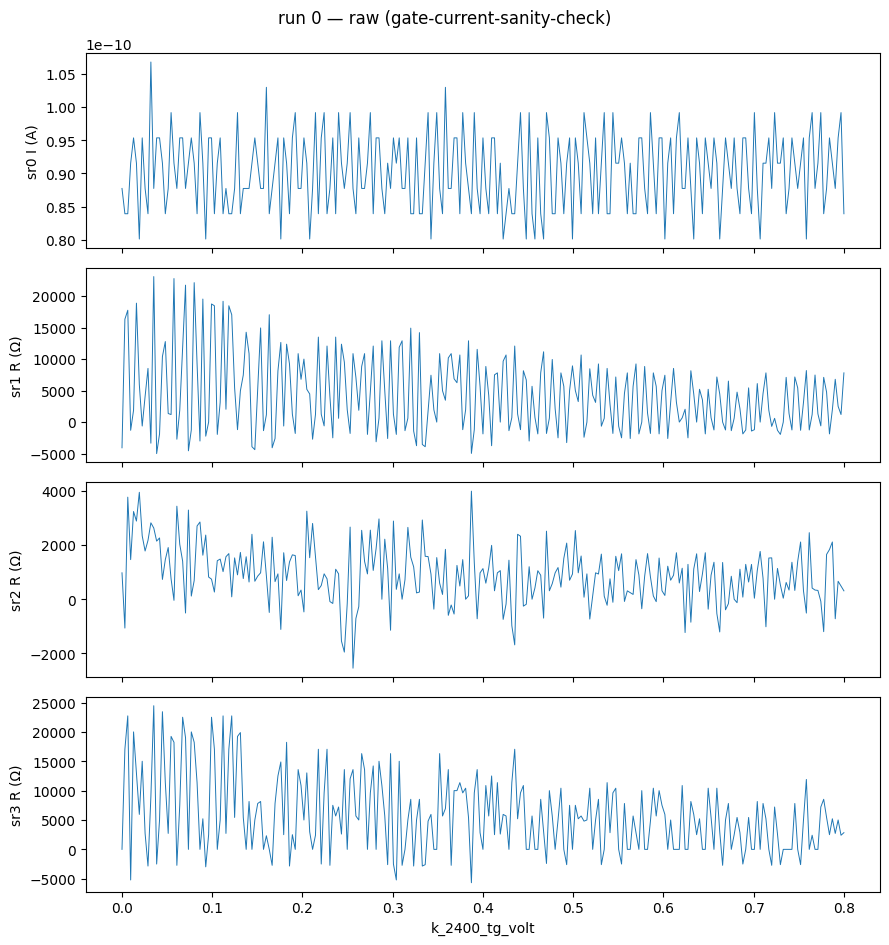

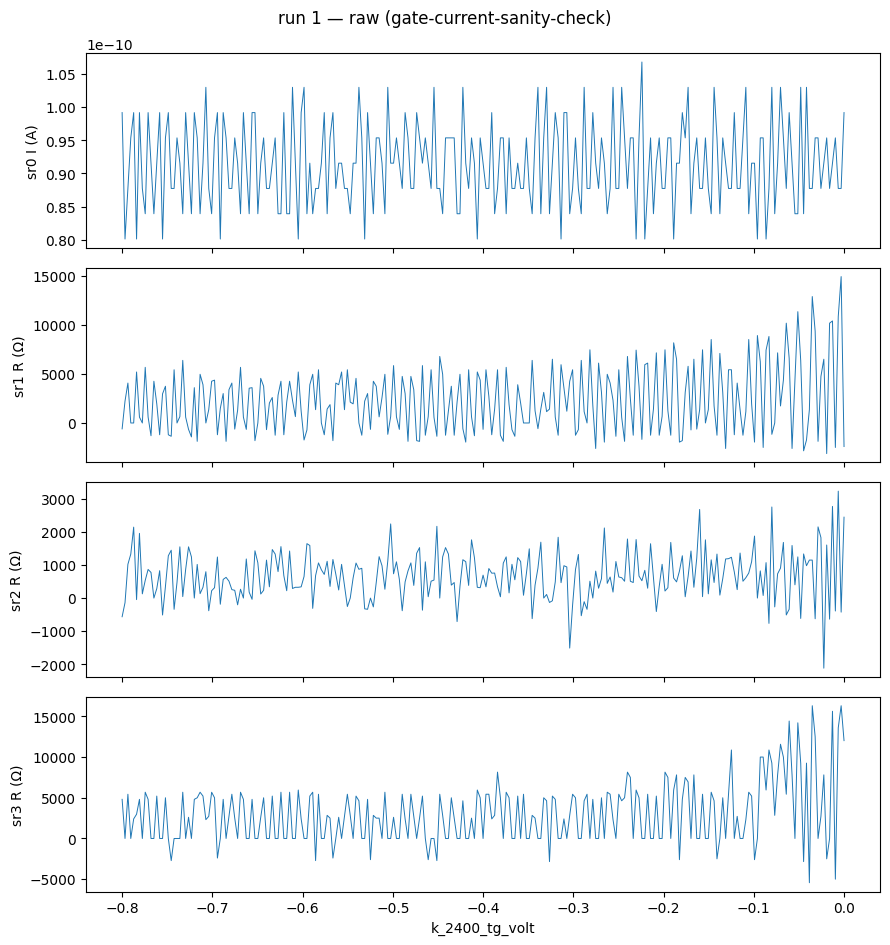

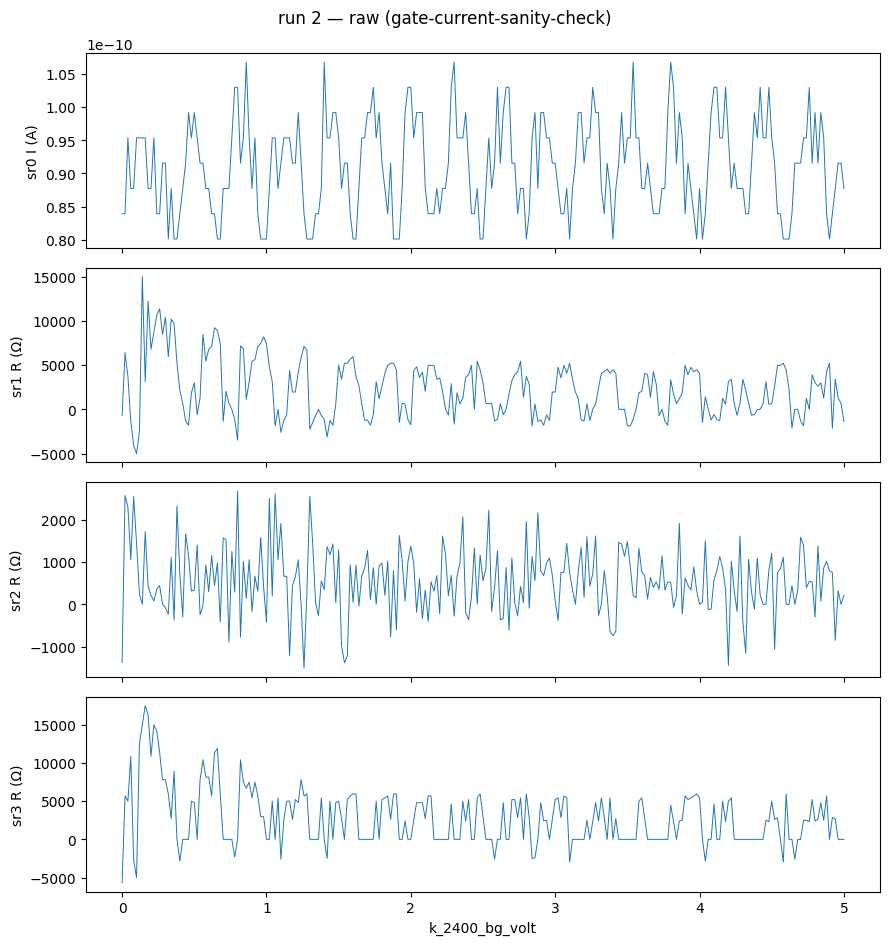

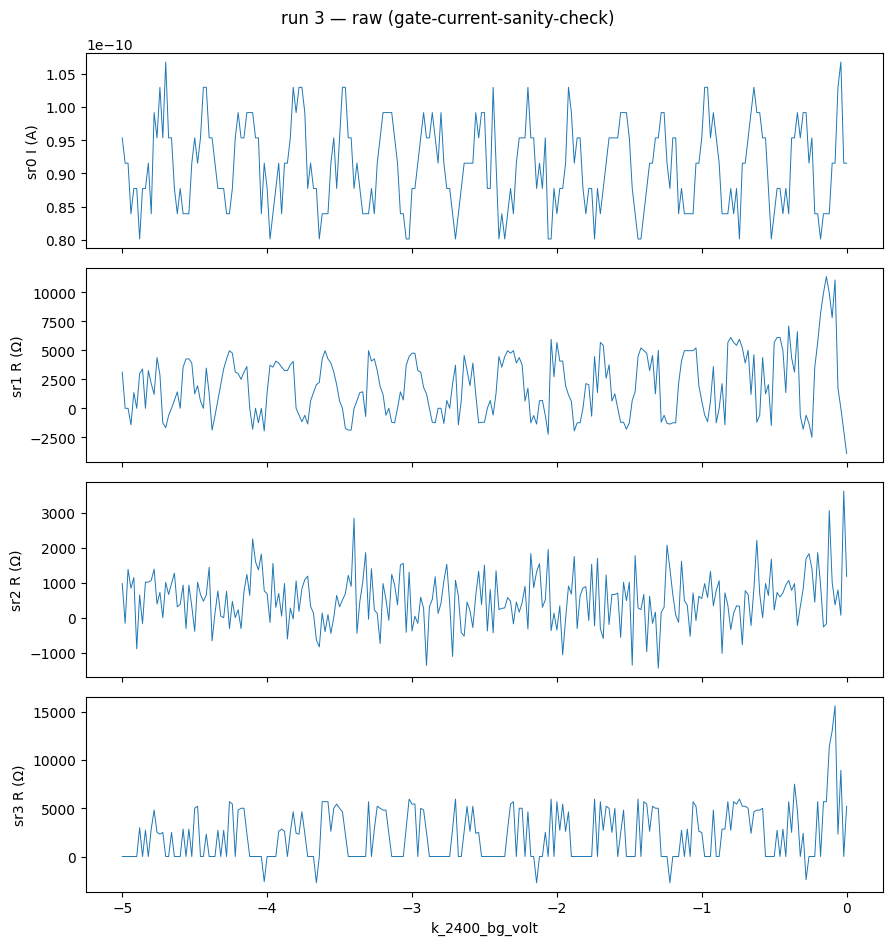

In [3]:
# Runs 0-3 — gate-current-sanity-check, raw view first
for i in range(4):
    g = run(i)
    print(summarize_run(g))
    plot_raw(g)


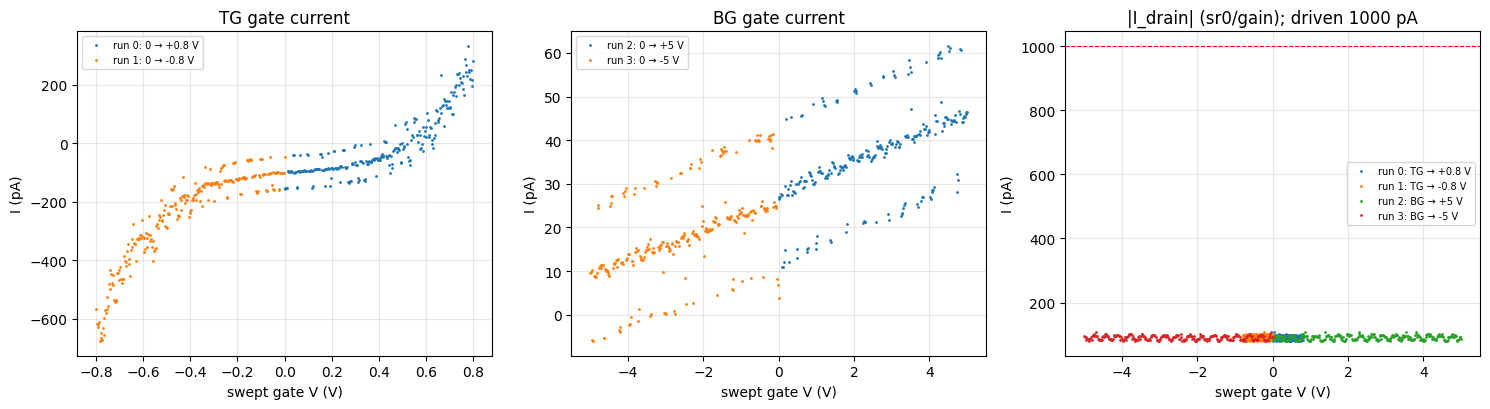

=== gate I-V ===
run 0 TG 0→+0.8 V: offset -97 pA, endpoint +282 pA (excess 379 pA), excess>100 pA beyond +0.51 V, local G(top 20%) 1119 pS
run 1 TG 0→-0.8 V: offset -101 pA, endpoint -565 pA (excess 464 pA), excess>100 pA beyond -0.39 V, local G(top 20%) 1952 pS
run 2 BG 0→+5 V: offset +27 pA, endpoint +46 pA (excess 19 pA), excess>100 pA beyond never, local G(top 20%) 7 pS
run 3 BG 0→-5 V: offset +25 pA, endpoint +10 pA (excess 15 pA), excess>100 pA beyond never, local G(top 20%) 9 pS

=== drain / 4T ===
run 0 TG→+0.8 V: |I_drain| 92 pA -> R_SD ~ 109 MOhm | sr1/2/3 med +298/+82/+477 nV (ADC-LSB multiples: unresolved)
run 1 TG→-0.8 V: |I_drain| 92 pA -> R_SD ~ 109 MOhm | sr1/2/3 med +179/+56/+238 nV (ADC-LSB multiples: unresolved)
run 2 BG→+5 V: |I_drain| 92 pA -> R_SD ~ 109 MOhm | sr1/2/3 med +179/+45/+238 nV (ADC-LSB multiples: unresolved)
run 3 BG→-5 V: |I_drain| 92 pA -> R_SD ~ 109 MOhm | sr1/2/3 med +179/+52/+238 nV (ADC-LSB multiples: unresolved)


In [4]:
# Runs 0-3 — Gate C reduction: gate I-V, drain current, Rxx resolution
SR0_GAIN = -1e6   # Ithaco (device card)
I_BIAS = 1e-9     # 10 mV drive / 10 MOhm bias resistor

legs = {0: ("TG", "k_2400_tg", "+0.8"), 1: ("TG", "k_2400_tg", "-0.8"),
        2: ("BG", "k_2400_bg", "+5"), 3: ("BG", "k_2400_bg", "-5")}

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
for i, (gname, inst, ep) in legs.items():
    g = run(i)
    v = g.col(f"{inst}_volt")
    ax = axs[0] if gname == "TG" else axs[1]
    ax.plot(v, g.col(f"{inst}_curr") * 1e12, ".", ms=2, label=f"run {i}: 0 → {ep} V")
    axs[2].plot(v, np.abs(g.col("sr0_X") / SR0_GAIN) * 1e12, ".", ms=2,
                label=f"run {i}: {gname} → {ep} V")
axs[0].set_title("TG gate current"); axs[1].set_title("BG gate current")
axs[2].set_title("|I_drain| (sr0/gain); driven 1000 pA")
axs[2].axhline(1000, color="r", ls="--", lw=0.8)
for ax in axs:
    ax.set_xlabel("swept gate V (V)"); ax.set_ylabel("I (pA)")
    ax.grid(alpha=0.3); ax.legend(fontsize=7)
fig.tight_layout(); plt.show()

print("=== gate I-V ===")
for i, (gname, inst, ep) in legs.items():
    g = run(i)
    v, ic = g.col(f"{inst}_volt"), g.col(f"{inst}_curr")
    o = np.argsort(np.abs(v)); v, ic = v[o], ic[o]
    i0 = np.median(ic[np.abs(v) < 0.05 * np.abs(v).max()])
    ex = np.abs(ic - i0)
    ex_s = np.convolve(ex, np.ones(7) / 7, mode="same")
    cross = v[ex_s > 100e-12]
    vc = f"{cross[np.argmin(np.abs(cross))]:+.2f} V" if len(cross) else "never"
    gloc = np.polyfit(v[int(0.8 * len(v)):], ic[int(0.8 * len(v)):], 1)[0]
    print(f"run {i} {gname} 0→{ep} V: offset {i0*1e12:+.0f} pA, endpoint {ic[-1]*1e12:+.0f} pA "
          f"(excess {ex[-1]*1e12:.0f} pA), excess>100 pA beyond {vc}, "
          f"local G(top 20%) {gloc*1e12:.0f} pS")

print()
print("=== drain / 4T ===")
for i, (gname, inst, ep) in legs.items():
    g = run(i)
    idr = np.median(np.abs(g.col("sr0_X") / SR0_GAIN))
    x1, x2, x3 = (np.median(g.col(f"{c}_X")) for c in ("sr1", "sr2", "sr3"))
    print(f"run {i} {gname}→{ep} V: |I_drain| {idr*1e12:.0f} pA -> R_SD ~ {0.010/idr/1e6:.0f} MOhm | "
          f"sr1/2/3 med {x1*1e9:+.0f}/{x2*1e9:+.0f}/{x3*1e9:+.0f} nV (ADC-LSB multiples: unresolved)")


> **00:02** · Gate C: BG clean; TG leak onset ~0.4-0.5 V (0.4-0.5 nA at +/-0.8 V); R\_SD 109 MOhm contact-limited at Vsi=0; stop-and-report

**Gate C verdict — stop-and-report (per recipe: never advance on a leaked gate).**

- **BG (k_2400_bg): PASS.** ≤61 pA out to ±5 V, ohmic ~8 pS (~130 GΩ) slope, symmetric. Clean to the card limit.
- **TG (k_2400_tg): FAIL (gross-safety).** Superlinear, near-symmetric leak turn-on: excess >100 pA beyond V_tg ≈ +0.51 / −0.39 V, reaching 380–460 pA excess at ±0.8 V with local G ≈ 1–2 nS and rising. Not the capacitive charging slope (est. <1 pA at this ramp rate) and not ohmic — defect/pinhole-mediated conduction through the 14.9 nm TG hBN. Below the 1 nA hard ceiling at the card limit, but a real leak inside the committed range.
- **Cross-gate: PASS.** Parked gate flat in all four legs.
- **Liveness: PARTIAL.** Device passes current (drain 92 pA stable) but is contact-limited: R_SD ≈ 109 MΩ, **unmodulated** by TG ±0.8 V or BG ±5 V — the bottleneck is outside the TG/BG-gated channel, i.e. the Si-gated lead/contact regions at V_si = 0. The three Rxx channels read ADC-quantization-level signals (~50–500 nV on 1 nA nominal), so 4T probe liveness is **unresolved, not failed** — re-judge after contact doping.

**Recommendation to operator:** (1) restrict the TG *working* window to |V_tg| ≤ 0.5 V (leak <100 pA); at D = 0 this caps |n| at ~1.1×10¹² cm⁻² (vs 1.8×10¹² at ±0.8 V) — TG is the binding gate at D = 0 either way; SAFETIES validators untouched (operator-owned). (2) Dope the contacts via V_si before the first gatemap — proposed: single ramped move to +15 V (DC205, 0.5 V/s) watching drain current recover; the systematic Si survey is blocklisted, so the approach needs your call. Cell B (nplci reset) deliberately not run per the recipe's leak branch.

## Runs 4–6 — Si surveys + first CNP cross-section

Runs 4–5: silicon-backgate-survey, 1D contact-doping flavor, ±20 V — **Si is inert on this device** (drain pinned ~88 pA both signs; no hysteresis on the 0…+20 overlap). Liveness-discriminator point reads (measure cell 41, exec 22): the S–D path is resistive and ohmic to 100 mV; at 100 mV drive the Rxx probes carry drive-proportional kΩ-scale signals ⇒ current traverses the bar and the ~109 MΩ is the **T_SD source contact** (sr1, which includes the B_SD interface, reads only ~kΩ). Campaign config going forward: 100 mV drive, **Rxx = sr_X / (sr0 current) per point** — nominal I_bias is invalid (contact R ≫ bias resistor); hera-watch nominal-R readings run ~10× low.

Run 6: TG cut at V_bg = 0 — **CNP found**: sr1/sr3 peak at **V_tg = +0.060 V**, R_peak ≈ 10 kΩ over 2–3 kΩ flanks; sr2 same shape, ~×0.15 scale, peak +0.020 V. Drain 0.99 nA ± 10%. Sensitivities resolve the ridge cleanly; measured rate 1.13 s/pt.

run 4
  type:    1D sweep
  recipe:  silicon-backgate-survey
  tags:    flavor: 1D k_si contact-doping; V_si 0 -> +20 V, TG=BG=0
  rows:    101 of 101 (complete)
  swept:   dc205_smart_voltage 0 → 20 (monotonic)
run 5
  type:    1D sweep
  recipe:  silicon-backgate-survey
  tags:    flavor: 1D k_si contact-doping; V_si +20 -> -20 V, TG=BG=0
  rows:    201 of 201 (complete)
  swept:   dc205_smart_voltage 20 → -20 (monotonic)


run 6
  type:    1D sweep
  recipe:  cnp-and-dline-calibration
  tags:    scoping: 1D TG cut at Vbg=0; CNP visibility + sensitivity calibration
  rows:    321 of 321 (complete)
  swept:   k_2400_tg_volt -0.8 → 0.8 (monotonic)


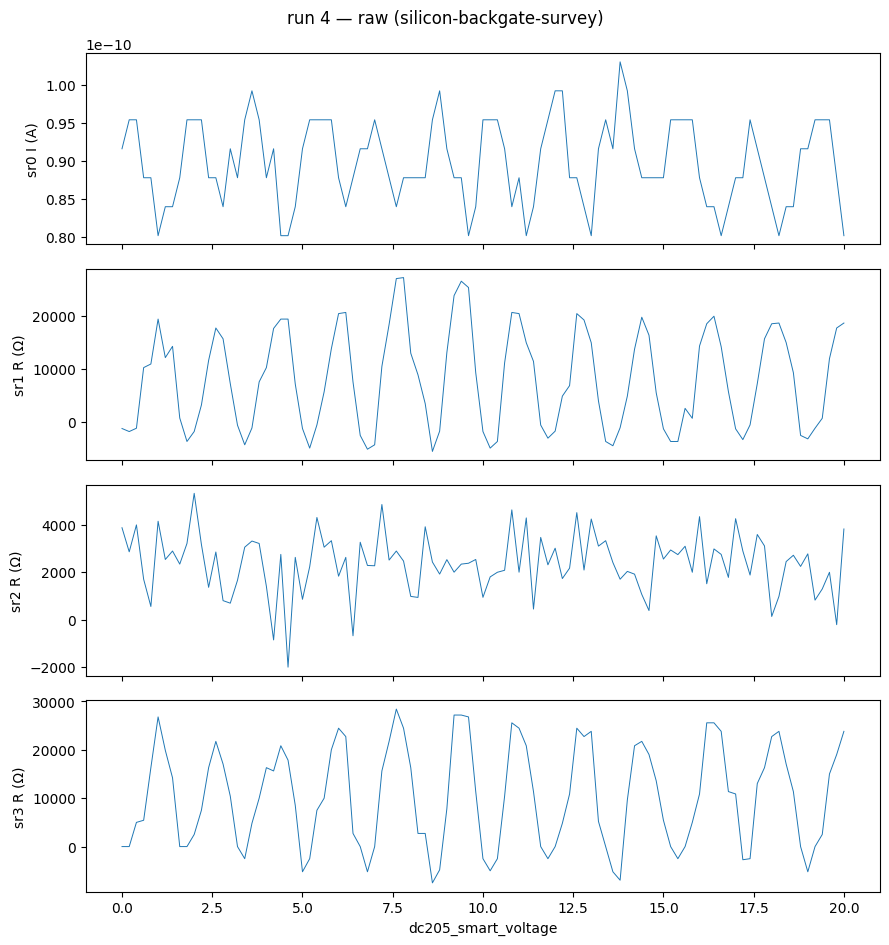

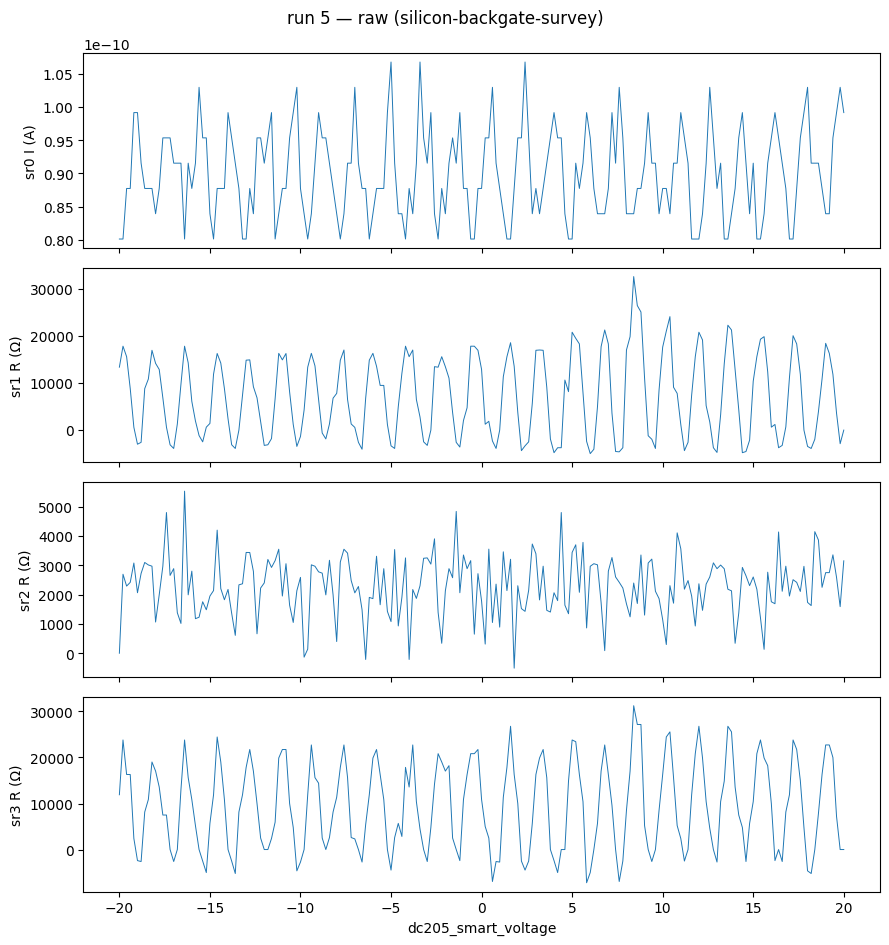

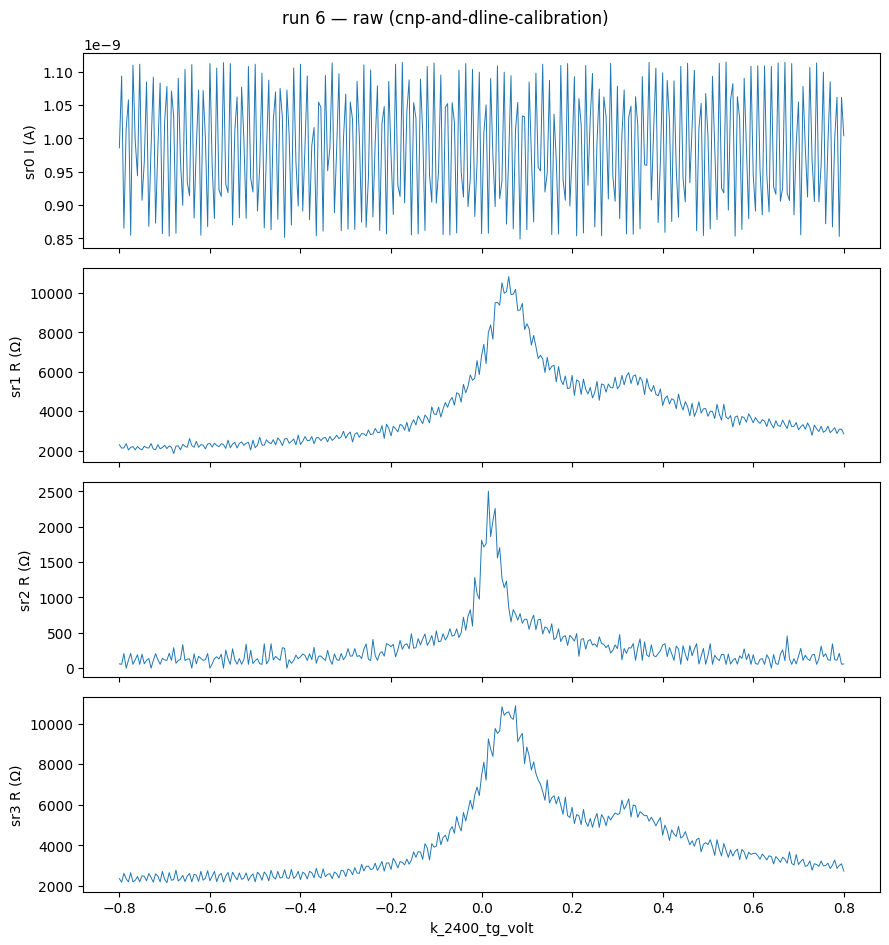

In [5]:
# Runs 4-6 — raw first: Si surveys (4: 0->+20, 5: +20->-20) and TG scoping cut (6)
for i in (4, 5, 6):
    g = run(i)
    print(summarize_run(g))
    plot_raw(g)


run 6 sr1: CNP V_tg=+0.060 V, R_peak=9.95 kΩ, flanks 2.14 / 3.07 kΩ
run 6 sr2: CNP V_tg=+0.020 V, R_peak=1.85 kΩ, flanks 0.12 / 0.17 kΩ
run 6 sr3: CNP V_tg=+0.060 V, R_peak=10.22 kΩ, flanks 2.39 / 3.04 kΩ


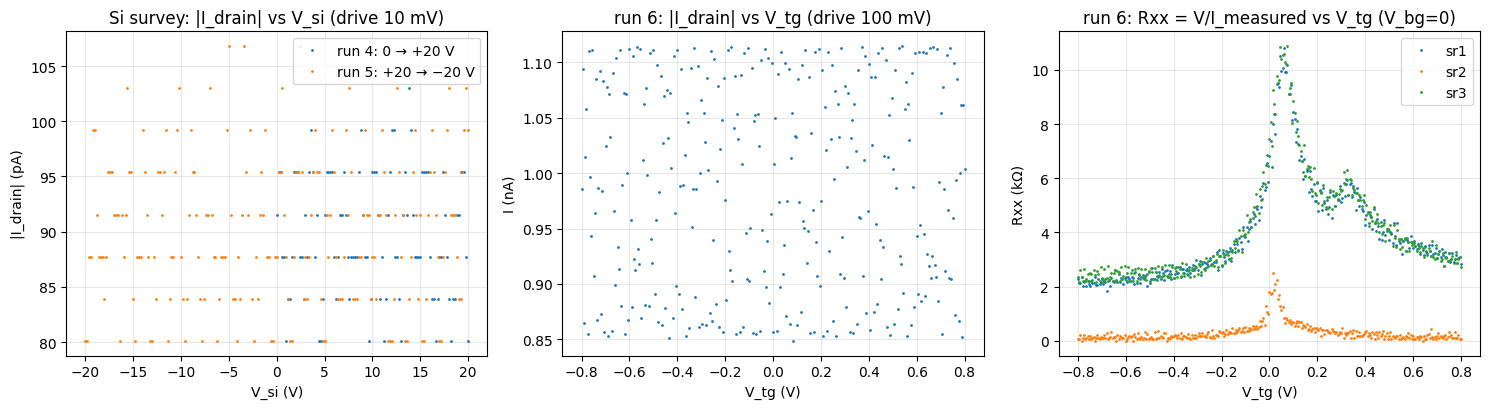

run 6 I_drain: med 0.99 nA (range 0.85–1.11)


In [6]:
# Runs 4-6 reduction: Si inertness + first CNP cross-section (per-point I normalization)
from scipy.ndimage import gaussian_filter1d
SR0_GAIN = -1e6

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
# Si surveys: drain current vs V_si
for i, lbl in ((4, "0 → +20 V"), (5, "+20 → −20 V")):
    g = run(i)
    axs[0].plot(g.col("dc205_smart_voltage"), np.abs(g.col("sr0_X") / SR0_GAIN) * 1e12,
                ".", ms=2, label=f"run {i}: {lbl}")
axs[0].set_title("Si survey: |I_drain| vs V_si (drive 10 mV)")
axs[0].set_xlabel("V_si (V)"); axs[0].set_ylabel("|I_drain| (pA)"); axs[0].legend()

# Run 6: normalized Rxx = sr_X / measured drain current
g = run(6)
v = g.col("k_2400_tg_volt")
i_dr = np.abs(g.col("sr0_X") / SR0_GAIN)
axs[1].plot(v, i_dr * 1e9, ".", ms=2)
axs[1].set_title("run 6: |I_drain| vs V_tg (drive 100 mV)")
axs[1].set_xlabel("V_tg (V)"); axs[1].set_ylabel("I (nA)")
for ch in ("sr1", "sr2", "sr3"):
    rx = g.col(f"{ch}_X") / i_dr
    axs[2].plot(v, rx / 1e3, ".", ms=2, label=ch)
    sm = gaussian_filter1d(rx, 3); pk = np.argmax(sm)
    print(f"run 6 {ch}: CNP V_tg={v[pk]:+.3f} V, R_peak={sm[pk]/1e3:.2f} kΩ, "
          f"flanks {sm[10]/1e3:.2f} / {sm[-10]/1e3:.2f} kΩ")
axs[2].set_title("run 6: Rxx = V/I_measured vs V_tg (V_bg=0)")
axs[2].set_xlabel("V_tg (V)"); axs[2].set_ylabel("Rxx (kΩ)"); axs[2].legend()
for ax in axs: ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()
print(f"run 6 I_drain: med {np.median(i_dr)*1e9:.2f} nA (range {i_dr.min()*1e9:.2f}–{i_dr.max()*1e9:.2f})")


## Run 7 — first 0 T gatemap + cnp-and-dline-calibration

TG ±0.8 (161, fast) × BG ±2.5 V (51, slow) at V_si = 0, 100 mV drive, 2.6 h. Raw first; then the CNP-line fit per channel (per-row smoothed argmax with edge-clip / no-ridge / 2σ-outlier guards, Rxx normalized by measured drain current per point), the (n, D) conversion, and the D = 0 designer.

run 7
  type:    2D sweep
  recipe:  gatemap
  tags:    first map, Vsi = 0V; feeds cnp-and-dline-calibration
  rows:    8211


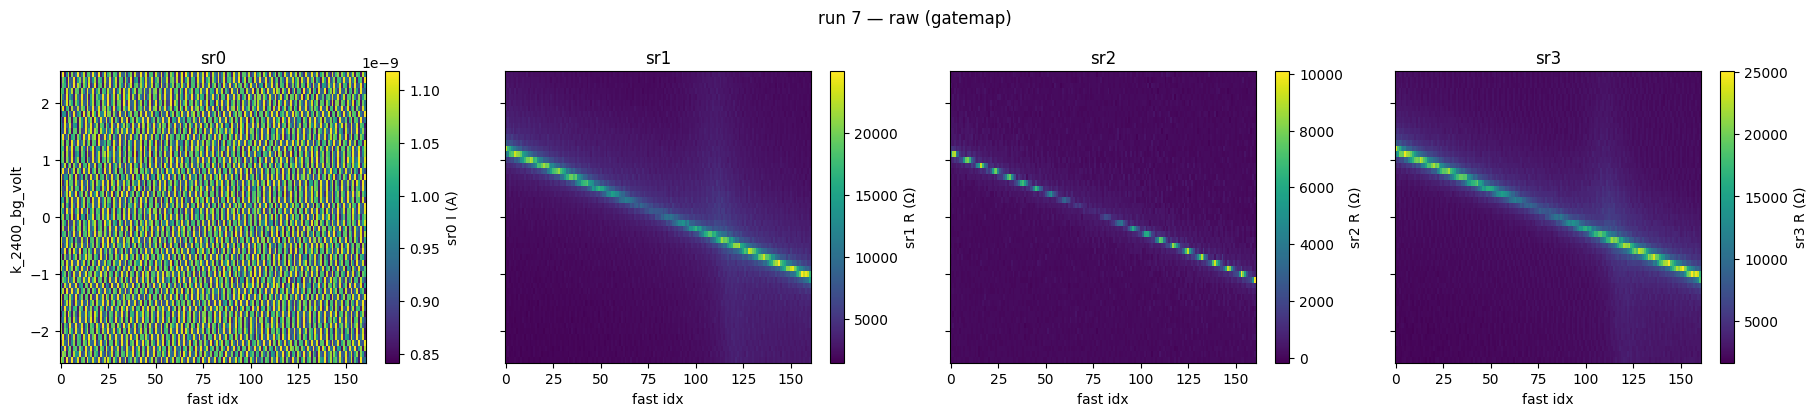

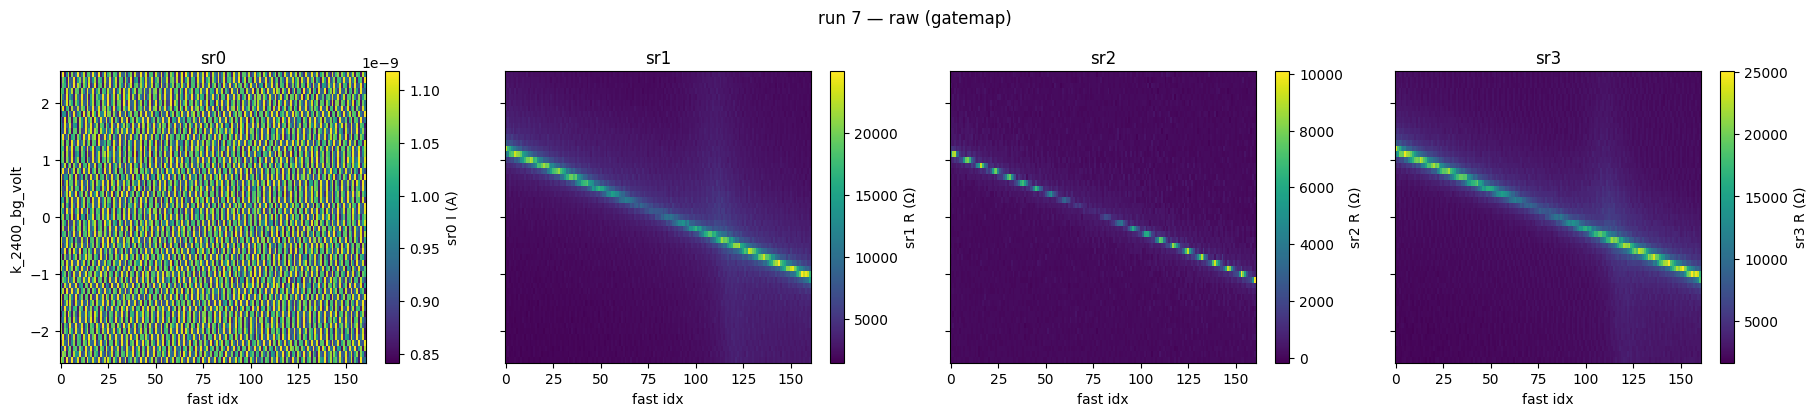

In [7]:
# Run 7 — first 0 T gatemap, raw view first
g = run(7)
print(summarize_run(g))
plot_raw(g)


I_drain over map: med 0.98 nA (0.84–1.12)
sr1: slope -0.7236, intercept +0.0552 V, rms 4.3 mV, rows 20/51
sr2: slope -0.7223, intercept +0.0139 V, rms 3.5 mV, rows 20/51
sr3: slope -0.7207, intercept +0.0515 V, rms 3.5 mV, rows 17/51

ratio c_bg/c_tg = 0.7222 (geometry prior 0.6963, +3.7%)
c_tg = 1.7827 mF/m² (ANCHOR, geometry prior) | c_bg = 1.2874 mF/m² (ratio-calibrated)
n_offset = -5.934e+14 m^-2 (-0.0593e12 cm^-2); D_offset = 0 (stated assumption)
closure: max|n| on ridge = 0.0000e12 cm^-2
D=0 realized window: n = -1.837 .. +1.720 e12 cm^-2 (V_bg only ±1.11 V — TG is the binding gate)
F_L(hole edge) = 19.0 T -> Δ(1/B) ≤ 1.75e-02 /T (1/3 Nyquist)
F_L(electron edge) = 17.8 T -> Δ(1/B) ≤ 1.87e-02 /T (1/3 Nyquist)


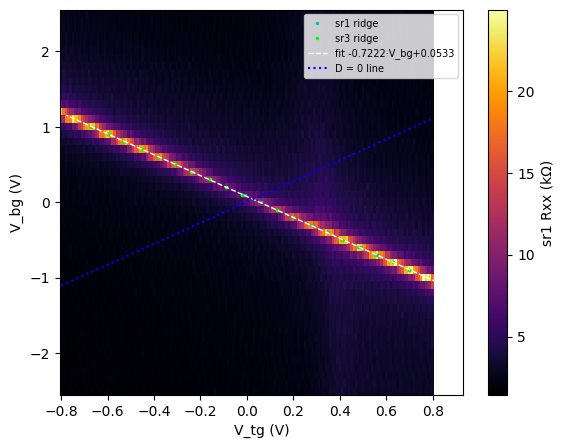

In [8]:
# Run 7 — cnp-and-dline-calibration: per-channel ridge fit -> (n, D) conversion
from scipy.ndimage import gaussian_filter1d
E = cst.e; EPS0 = cst.epsilon_0
NFAST = 161
g = run(7)
vt, vb = g.col("k_2400_tg_volt"), g.col("k_2400_bg_volt")
i_dr = np.abs(g.col("sr0_X")) / 1e6                      # measured drain current
gr = lambda c: c[:len(c) // NFAST * NFAST].reshape(-1, NFAST)
VT, VB, IDR = gr(vt), gr(vb), gr(i_dr)
nrows = VT.shape[0]
print(f"I_drain over map: med {np.median(IDR)*1e9:.2f} nA ({IDR.min()*1e9:.2f}–{IDR.max()*1e9:.2f})")

# ridge extraction per channel (fast axis = V_tg; rows = V_bg) with the three
# step-1 guards: edge-clip, no-clear-ridge, 2σ iterative outlier rejection
fits = {}
for ch in ("sr1", "sr2", "sr3"):
    R = gr(g.col(f"{ch}_X")) / IDR
    rows_v, ridge_v = [], []
    for j in range(nrows):
        sm = gaussian_filter1d(R[j], 3); k = int(np.argmax(sm))
        if 5 < k < NFAST - 6 and sm[k] > 2 * np.median(sm):
            rows_v.append(VB[j, 0]); ridge_v.append(VT[j, k])
    rows_v, ridge_v = np.array(rows_v), np.array(ridge_v)
    m = np.ones(len(rows_v), bool)
    for _ in range(3):
        p = np.polyfit(rows_v[m], ridge_v[m], 1)
        res = ridge_v - np.polyval(p, rows_v)
        m = np.abs(res) < 2 * max(res[m].std(), 1e-4)
    p = np.polyfit(rows_v[m], ridge_v[m], 1)
    fits[ch] = (p[0], p[1], (ridge_v - np.polyval(p, rows_v))[m].std(), int(m.sum()), rows_v[m], ridge_v[m])
    print(f"{ch}: slope {p[0]:+.4f}, intercept {p[1]:+.4f} V, rms {fits[ch][2]*1e3:.1f} mV, rows {m.sum()}/{nrows}")

# conversion — axis orientation: ridge V_tg vs rows V_bg => c_bg/c_tg = -slope.
# Anchor: TG at its stack prior (single 14.9 nm hBN dielectric); sr2 (weak short
# channel) reported but not driving; sr1/sr3 spread 0.4% => one calibration.
slope = float(np.mean([fits["sr1"][0], fits["sr3"][0]]))
b = float(np.mean([fits["sr1"][1], fits["sr3"][1]]))
c_tg_cal = EPS0 * 3.0 / 14.9e-9
c_bg_cal = -slope * c_tg_cal
n_off = -(c_tg_cal * b) / E
cal = GateCalibration(c_tg_cal, c_bg_cal, n_offset=n_off, D_offset=0.0)
print(f"\nratio c_bg/c_tg = {-slope:.4f} (geometry prior 0.6963, {(-slope/0.6963-1)*100:+.1f}%)")
print(f"c_tg = {c_tg_cal*1e3:.4f} mF/m² (ANCHOR, geometry prior) | c_bg = {c_bg_cal*1e3:.4f} mF/m² (ratio-calibrated)")
print(f"n_offset = {n_off:.3e} m^-2 ({n_off*1e-16:+.4f}e12 cm^-2); D_offset = 0 (stated assumption)")
vv = np.linspace(-1.1, 1.15, 50)
print(f"closure: max|n| on ridge = {np.abs(cal.density(slope*vv+b, vv)).max()*1e-16:.4f}e12 cm^-2")

# D=0 designer, clip by dropping (validators ±0.8 / ±5.0)
ns = np.linspace(-2.5e16, 2.5e16, 2001)
q = E * (ns - n_off) / 2.0
Vt_l, Vb_l = q / c_tg_cal, q / c_bg_cal
keep = (np.abs(Vt_l) <= 0.8) & (np.abs(Vb_l) <= 5.0)
print(f"D=0 realized window: n = {ns[keep].min()*1e-16:+.3f} .. {ns[keep].max()*1e-16:+.3f} e12 cm^-2 "
      f"(V_bg only ±{np.abs(Vb_l[keep]).max():.2f} V — TG is the binding gate)")
for tag, nv in (("hole", ns[keep].min()), ("electron", ns[keep].max())):
    FL = cst.h * abs(nv) / (4 * E)
    print(f"F_L({tag} edge) = {FL:.1f} T -> Δ(1/B) ≤ {1/(3*FL):.2e} /T (1/3 Nyquist)")

# overlay: fit + D=0 line on the sr1 map
fig, ax = plt.subplots(figsize=(6.5, 5))
R1 = gr(g.col("sr1_X")) / IDR
pm = ax.pcolormesh(VT, VB, R1 / 1e3, shading="nearest", cmap="inferno")
fig.colorbar(pm, ax=ax, label="sr1 Rxx (kΩ)")
for ch, c in (("sr1", "c"), ("sr3", "lime")):
    ax.plot(fits[ch][5], fits[ch][4], ".", color=c, ms=3, label=f"{ch} ridge")
ax.plot(slope * vv + b, vv, "w--", lw=1, label=f"fit {slope:+.4f}·V_bg{b:+.4f}")
ax.plot(Vt_l[keep], Vb_l[keep], "b:", lw=1.5, label="D = 0 line")
ax.set_xlabel("V_tg (V)"); ax.set_ylabel("V_bg (V)"); ax.legend(fontsize=7)
plt.show()


> **14:38** · Calibration: ratio 0.7222 (data) / scale geometry-anchored; n\_off -0.059e12; D=0 window -1.84..+1.72e12; F\_L edge ~19 T

**Read — calibration contract (run 7).** CNP line clean and single across the window; sr1/sr3 slopes agree to 0.4% (one calibration for the device; sr2 — the short weak pair — matches in slope, intercept offset −40 mV reported, not driving). **Two-tier provenance**: ratio **c_bg/c_tg = 0.7222 data-calibrated** (vs 0.6963 geometry, +3.7% — geometry sanity passes); **absolute scale = geometry prior** (c_tg anchored at 14.9 nm hBN), pending the quantum-Hall lever-arm upgrade (ray slopes must quantize, dn/dB = ν·e/h). n_offset = −0.059×10¹² cm⁻² (V_tg intercept +0.053 V); D_offset = 0 is a stated assumption. Closure exact. **D = 0 window: n ∈ [−1.84, +1.72]×10¹² cm⁻²** — TG binds; V_bg never exceeds ±1.11 V. Feasibility (investigation step 2): F_L at the window edges 17.8–19.0 T → Δ(1/B) ≤ 1.8×10⁻² /T. Side notes for step 3: CNP peak R grows with |D| along the ridge (~25 kΩ by V_bg = −1 vs ~10 kΩ at V_bg = 0) — carried to the per-channel D-systematics later, not read now (domain caveat). Faint TG-only vertical feature near V_tg ≈ +0.35–0.4 V (singly-gated arm region); away from the D = 0 corridor's low-|n| half.

## Run 8 — SdH spot check, hole side (n = −1.8×10¹², D = 0, B 0.8→9 T)

746 pts uniform-B (11 mT), delay 1 s, drive 100 mV, no clipping (fs ≤ 0.04). Raw first, then onset + FFT with stability sweep and forward-model overlay.

run 8
  type:    1D sweep
  recipe:  sdh-spot-check
  tags:    hole side: n = -1.8e12, D = 0, (Vtg, Vbg) = (-0.7822, -1.0832)
  rows:    746 of 746 (complete)
  swept:   magnet_field 0.8 → 9 (monotonic)


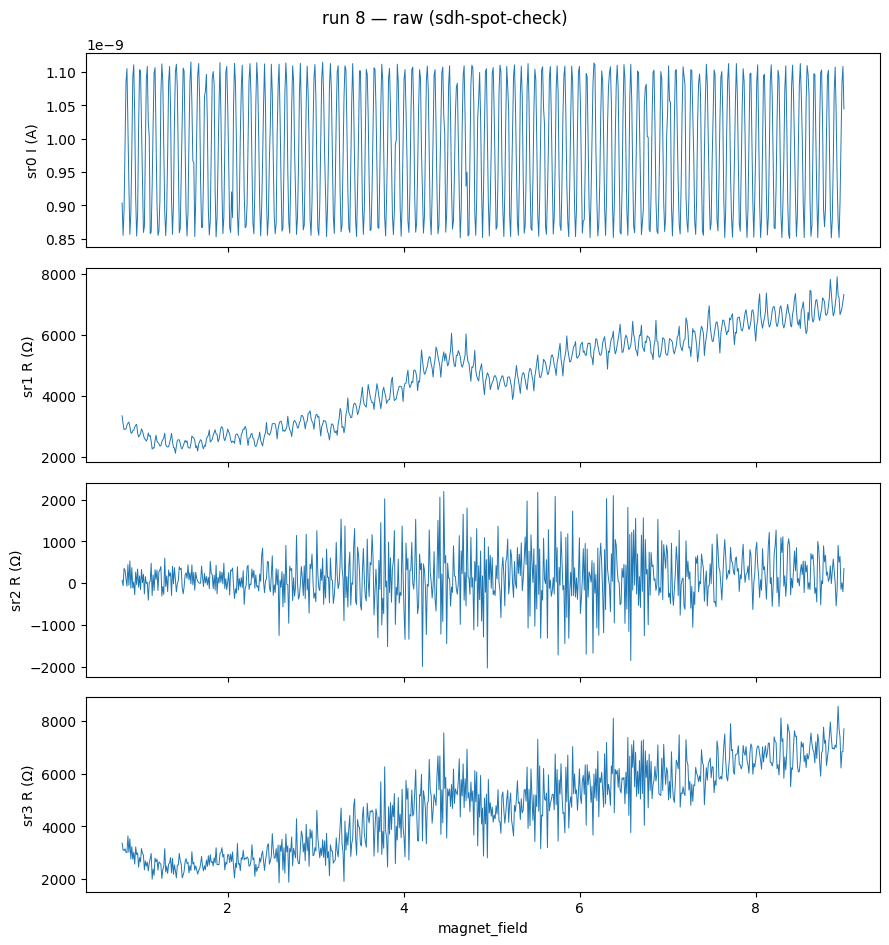

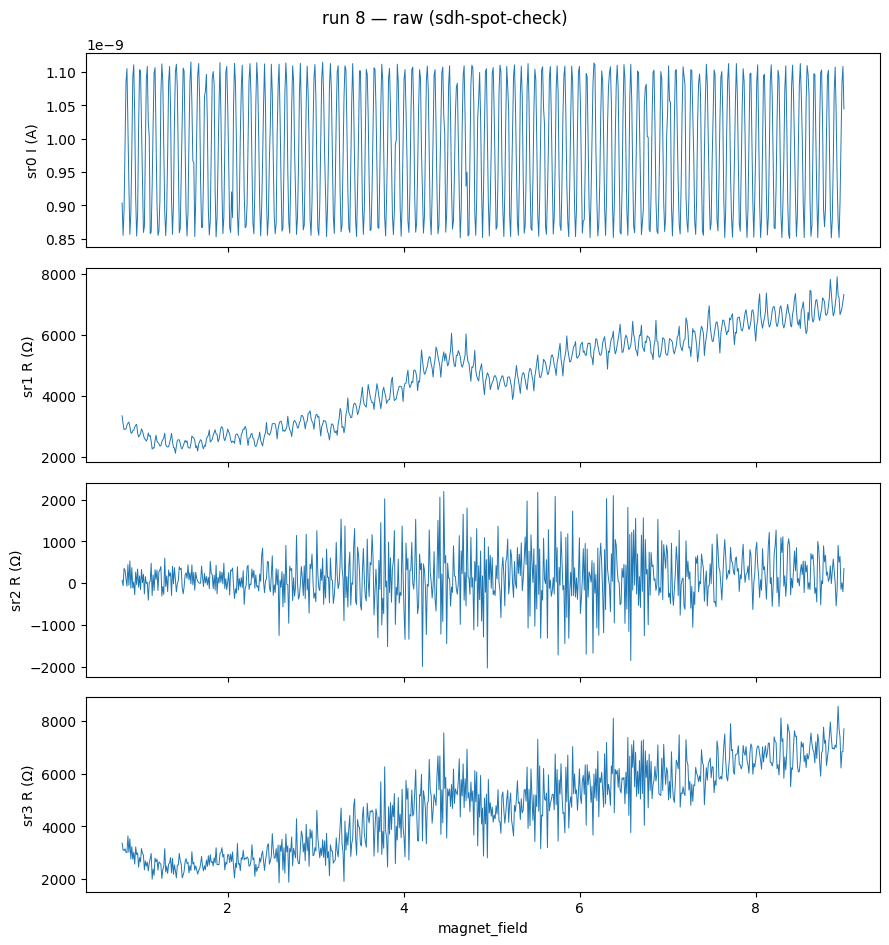

In [9]:
# Run 8 — SdH spot check, hole side (n=-1.8e12, D=0, B 0.8->9 T): raw first
g = run(8)
print(summarize_run(g))
plot_raw(g)


C:\Users\DGG\AppData\Local\Temp\ipykernel_34888\2021040786.py:16: UserWarning: sdh_onset: untracked tone(s): 11.4 T (never above threshold (max SNR 4.7 vs 5 across 5 windows))
  on = sdh_onset(R, B, r_full_scale=fs / 1e-9)
C:\Users\DGG\AppData\Local\Temp\ipykernel_34888\2021040786.py:16: UserWarning: sdh_onset: marginal tone 4.4 T would carry the onset (0.80 T) — excluded; onset_b = 1.67 T from the 7.3 T tone
  on = sdh_onset(R, B, r_full_scale=fs / 1e-9)


--- sr1 ---
sdh_onset: onset_b = 1.67 T (tone 7.3 T) over B [0.80, 9.00] T
  tone   17.7 T: onset  2.26 T  dF  3.03 T  snr_max   18.9  [revives-below-gap, ~4x4.4T, 19x->331.8T]
  tone    7.3 T: onset  1.67 T  dF  2.05 T  snr_max   13.9  [6x->46.1T, 20x->149.4T]
  tone    4.4 T: onset  0.80 T  dF  0.88 T  snr_max    6.1  [censored@edge, marginal, near-residual, 4x->17.7T, 6x->25.6T]
  tone   25.6 T: onset  1.45 T  dF  1.73 T  snr_max    5.6  [marginal, ~6x4.4T]
  tone   46.1 T: onset  1.91 T  dF  2.42 T  snr_max    6.2  [marginal, ~6x7.3T]
  tone  149.4 T: onset  3.32 T  dF  5.26 T  snr_max   10.5  [~20x7.3T]
  tone  331.8 T: onset  4.79 T  dF 10.25 T  snr_max   10.4  [~19x17.7T]
  tone   11.4 T: UNTRACKED — never above threshold (max SNR 4.7 vs 5 across 5 windows)
--- sr3 --- SdhOnsetError: tones found but none trackable: 31.5 T — never above threshold (max SNR 3.3 vs 5 across 19 windows); 20.4 T — never above threshold (max SNR 3.2 vs 5 across 11 windows); 14.5 T — never above thresho

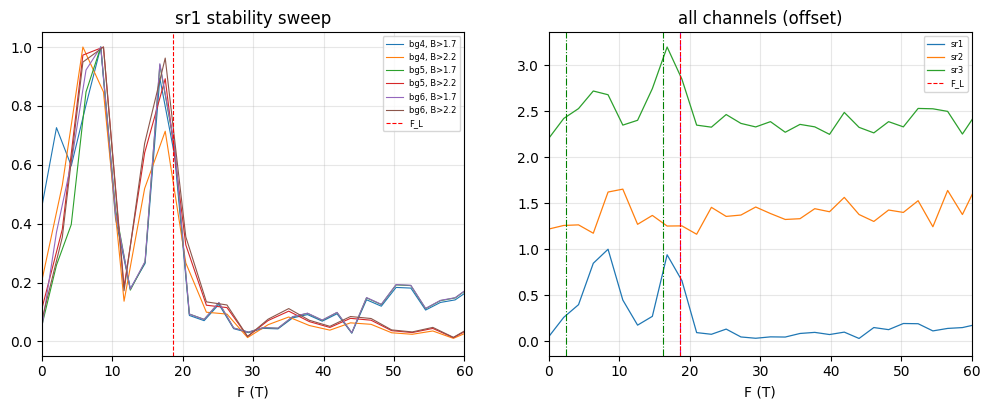

model: ABA pair ['2.4', '16.2'] T (green), ABC singleton 18.6 T (magenta), F_L=18.6 (red)


In [10]:
# Run 8 — onset + FFT read vs F_L and the forward model
import sys
sys.path.insert(0, str(Path.home() / "measurement_env/hera/models/trilayer_fs_count"))
from fs_count_b0 import aba_fs, abc_fs
from hera.analysis import sdh_onset

g = run(8)
B = g.col("magnet_field")
i_dr = np.abs(g.col("sr0_X")) / 1e6
FL = 18.6  # (h/4e)*1.8e16, geometry-anchored scale

# onset per channel (r_full_scale so a soft-clip truncates, not corrupts)
for ch, fs in (("sr1", 200e-6), ("sr3", 200e-6)):
    R = g.col(f"{ch}_X") / i_dr
    try:
        on = sdh_onset(R, B, r_full_scale=fs / 1e-9)
        print(f"--- {ch} ---"); print(on.summary())
    except Exception as e:
        print(f"--- {ch} --- {type(e).__name__}: {e}")

# FFT: stability sweep + all channels vs F_L
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
R1 = (g.col("sr1_X") / i_dr)[:, None]
for bg in (4, 5, 6):
    for lo in (1.7, 2.2):
        f, s = sdh_fft(R1, B, b_range=(lo, 9.0), bg_degree=bg)
        axs[0].plot(f, s[0] / s[0].max(), lw=0.8, label=f"bg{bg}, B>{lo}")
axs[0].set_title("sr1 stability sweep")
for ch, off in (("sr1", 0), ("sr2", 1.1), ("sr3", 2.2)):
    Rc = (g.col(f"{ch}_X") / i_dr)[:, None]
    f, s = sdh_fft(Rc, B, b_range=(1.7, 9.0), bg_degree=5)
    axs[1].plot(f, s[0] / s[0].max() + off, lw=0.9, label=ch)
axs[1].set_title("all channels (offset)")
# model overlays: ABA pair (hole side) and ABC singleton
efa, orb = aba_fs(-1.8e16)
for F, _ in orb:
    axs[1].axvline(F, color="g", ls="-.", lw=0.8)
_, _, _, _, Ftot = abc_fs(-1.8e16)
axs[1].axvline(Ftot, color="m", ls="-.", lw=0.8)
for ax in axs:
    ax.axvline(FL, color="r", ls="--", lw=0.8, label="F_L")
    ax.set_xlim(0, 60); ax.set_xlabel("F (T)"); ax.grid(alpha=0.3); ax.legend(fontsize=6)
plt.show()
print(f"model: ABA pair {[f'{F:.1f}' for F, _ in orb]} T (green), ABC singleton {Ftot:.1f} T (magenta), F_L={FL} (red)")


> **16:46** · run 8: onset 1.7 T; tones {8, 17} T robust + weak 25 sum; fork ABA-pair/ABC-singleton/harmonic carried; run 9 + LK masses discriminate

**Read — run 8 (hole side, n = −1.8×10¹², D = 0).** Onset ≈ 1.7 T (sr1). Two robust tones, stable across bg_degree × cutoff (real, not extraction artifacts): **f_a ≈ 7.3–8.4 T** and **f_b ≈ 16.8–17.7 T**, with a weak line at ≈25 ≈ f_a+f_b (sum/mixing) and a sub-threshold 11.4 T. δF is onset-limited at ~2–3 T (raising B_max buys nothing). **All three channels agree on the peak positions** (sr3/sr2 lower SNR, same content) — one region story so far, no mosaic flag.

**Template comparison (scale pinned by the whole set, per the investigation):**
- ABA (model: pair {2.4, 16.2} T, hole side): measured {f_a, f_b} as the pair sums to ~25 = 1.35×F_L — outside the plausible scale band; as a scale-free partition, f_a/(f_a+f_b) ≈ 33% vs predicted 13%. Strained, but the model's ML fraction carries wide γ error bars. The {7.3, 11.4} pairing sums to F_L (+0.5%) with f_b as a breakdown/sum tone — but 11.4 is sub-threshold and the "sum" tone would be the strongest in the set at all B.
- ABC (model: singleton 18.6 T): f_b alone fits at scale 0.92 ✓, but leaves the robust f_a unexplained — a real second frequency breaks the clean singleton count.
- f_b ≈ 2f_a within δF: the harmonic reading is NOT excluded by frequency alone; against it, thermal damping at T_e ≈ 8 K should suppress a 2nd harmonic well below its fundamental, and here the two amplitudes are comparable.

**Fork (STYLE 14) — carried, not resolved:** {f_a, f_b} = ABA pair at a red-flag scale | f_b = ABC singleton + f_a unexplained | {7.3, 11.4} ABA pair + f_b breakdown. Discriminators queued: (1) run 9 (electron side, in flight): ABA predicts the small pocket collapses to 0.3 T there — a mirrored f_a disfavors ABA; (2) per-branch LK masses (model: ABA {0.010, 0.060} vs ABC 0.108 mₑ) via temperature-dependence Flavor B; (3) F(n) from the fan.


## Run 9 — SdH spot check, electron side + cross-side read + D = 0 locator

run 9
  type:    1D sweep
  recipe:  sdh-spot-check
  tags:    electron side: n = +1.7e12, D = 0, (Vtg, Vbg) = (+0.7906, +1.0947)
  rows:    746 of 746 (complete)
  swept:   magnet_field 9 → 0.8 (monotonic)
--- sr1 ---
sdh_onset: onset_b = 3.69 T (tone 183.7 T) over B [0.80, 9.00] T
  tone    8.1 T: onset  1.52 T  dF  1.83 T  snr_max    5.3  [marginal, 2x->16.0T, 3x->24.0T, 4x->32.0T, 9x->75.2T, 23x->183.7T, 33x->265.2T]
  tone   16.0 T: onset  2.21 T  dF  2.93 T  snr_max    9.4  [marginal, ~2x8.1T]
  tone    5.1 T: onset  0.80 T  dF  0.88 T  snr_max   17.1  [censored@edge, near-residual]
  tone   24.0 T: onset  3.95 T  dF  7.05 T  snr_max    6.1  [marginal, ~3x8.1T]
  tone  183.7 T: onset  3.69 T  dF  6.27 T  snr_max   18.4  [~23x8.1T]
  tone  265.2 T: onset  4.25 T  dF  8.05 T  snr_max   14.3  [revives-below-gap, ~33x8.1T]
  tone   32.0 T: onset  3.92 T  dF  6.93 T  snr_max    5.5  [marginal, ~4x8.1T]
  tone   75.2 T: onset  2.48 T  dF  3.43 T  snr_max    8.8  [marginal, ~9x8.1T]
---

C:\Users\DGG\AppData\Local\Temp\ipykernel_34888\3269676004.py:11: UserWarning: sdh_onset: near-residual tone 5.1 T would carry the onset (0.80 T) — excluded; onset_b = 3.69 T from the 183.7 T tone
  on = sdh_onset(R, B, r_full_scale=fs / 1e-9)
C:\Users\DGG\AppData\Local\Temp\ipykernel_34888\3269676004.py:11: UserWarning: sdh_onset: untracked tone(s): 6.9 T (never above threshold (max SNR 0.9 vs 5 across 1 windows)); 23.4 T (never above threshold (max SNR 2.6 vs 5 across 13 windows)); 40.8 T (never above threshold (max SNR 4.2 vs 5 across 26 windows)); 30.1 T (never above threshold (max SNR 3.3 vs 5 across 18 windows))
  on = sdh_onset(R, B, r_full_scale=fs / 1e-9)
C:\Users\DGG\AppData\Local\Temp\ipykernel_34888\3269676004.py:11: UserWarning: sdh_onset: tone 5.1 T is above threshold through the lowest window — oscillations persist to the record's low edge; onset_b = 0.80 T is the record edge, not a measured die-off
  on = sdh_onset(R, B, r_full_scale=fs / 1e-9)


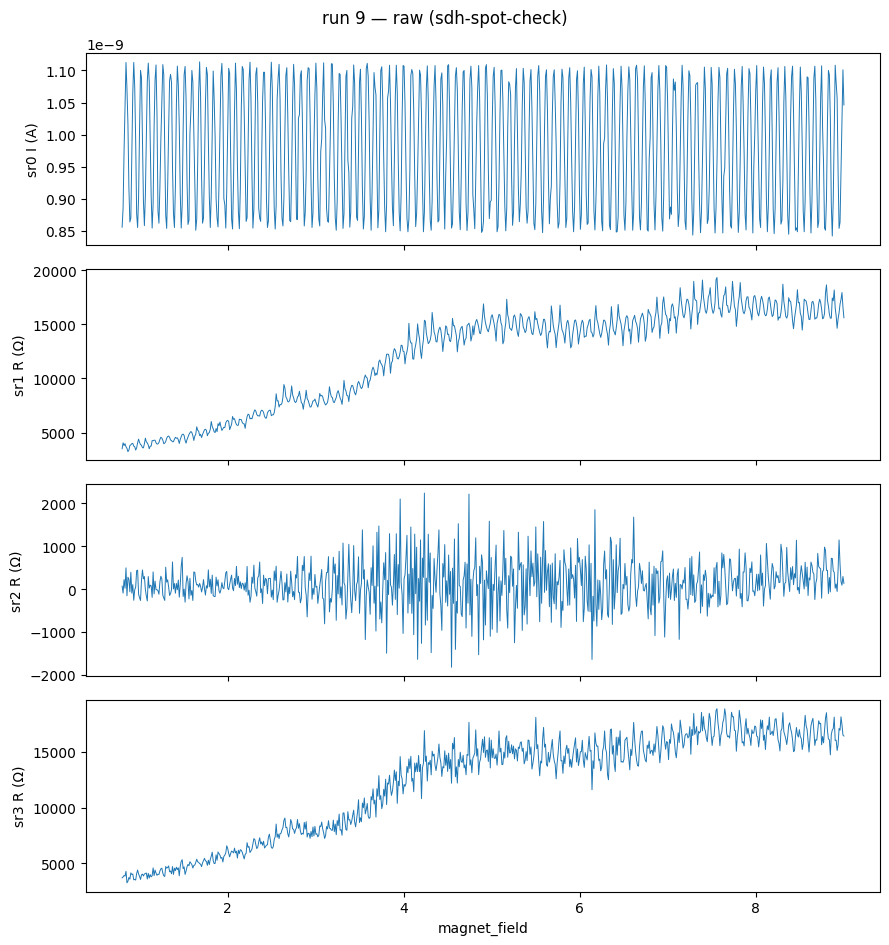

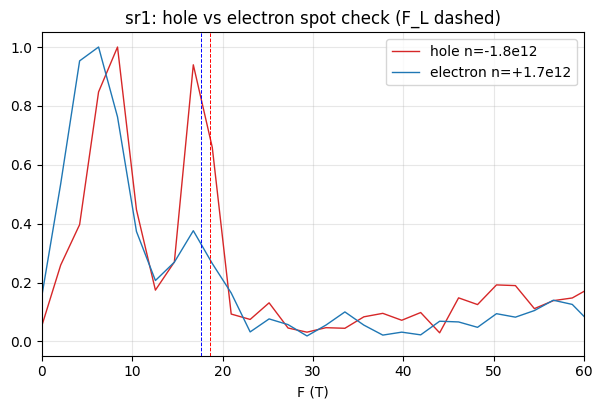

sr1: R_CNP minimum at nominal D = -0.0083 V/nm
sr3: R_CNP minimum at nominal D = -0.0093 V/nm


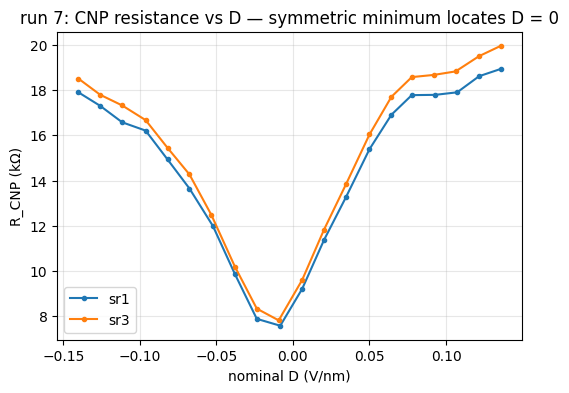

In [11]:
# Run 9 — electron spot check read + cross-side comparison + D=0 locator
from hera.analysis import sdh_onset
g = run(9)
print(summarize_run(g))
plot_raw(g)
B = g.col("magnet_field")
i_dr = np.abs(g.col("sr0_X")) / 1e6
for ch, fs in (("sr1", 200e-6), ("sr3", 200e-6)):
    R = g.col(f"{ch}_X") / i_dr
    try:
        on = sdh_onset(R, B, r_full_scale=fs / 1e-9)
        print(f"--- {ch} ---"); print(on.summary())
    except Exception as e:
        print(f"--- {ch} --- {type(e).__name__}: {e}")

# cross-side FFT comparison (sr1), same window
fig, ax = plt.subplots(figsize=(7, 4.2))
for rid, lbl, c in ((8, "hole n=-1.8e12", "tab:red"), (9, "electron n=+1.7e12", "tab:blue")):
    gg = run(rid)
    Bx = gg.col("magnet_field"); ii = np.abs(gg.col("sr0_X")) / 1e6
    f, s = sdh_fft((gg.col("sr1_X") / ii)[:, None], Bx, b_range=(1.7, 9.0), bg_degree=5)
    ax.plot(f, s[0] / s[0].max(), color=c, lw=1, label=lbl)
ax.axvline(18.6, color="r", ls="--", lw=0.7); ax.axvline(17.6, color="b", ls="--", lw=0.7)
ax.set_xlim(0, 60); ax.set_xlabel("F (T)"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("sr1: hole vs electron spot check (F_L dashed)")
plt.show()

# D = 0 locator from run 7: R_CNP along the ridge vs nominal D
from scipy.ndimage import gaussian_filter1d
g7 = run(7); NF = 161
gr = lambda c: c[:len(c) // NF * NF].reshape(-1, NF)
VT, VB = gr(g7.col("k_2400_tg_volt")), gr(g7.col("k_2400_bg_volt"))
IDR = gr(np.abs(g7.col("sr0_X")) / 1e6)
fig, ax = plt.subplots(figsize=(6, 4))
for ch in ("sr1", "sr3"):
    R = gr(g7.col(f"{ch}_X")) / IDR
    pts = []
    for j in range(VT.shape[0]):
        sm = gaussian_filter1d(R[j], 3); k = int(np.argmax(sm))
        if 5 < k < NF - 6 and sm[k] > 2 * np.median(sm):
            Dn = cal.displacement_field(VT[j, k], VB[j, 0]) / 1e9
            pts.append((Dn, sm[k]))
    pts = np.array(pts)
    ax.plot(pts[:, 0], pts[:, 1] / 1e3, "o-", ms=3, label=ch)
    print(f"{ch}: R_CNP minimum at nominal D = {pts[np.argmin(pts[:,1]),0]:+.4f} V/nm")
ax.set_xlabel("nominal D (V/nm)"); ax.set_ylabel("R_CNP (kΩ)"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("run 7: CNP resistance vs D — symmetric minimum locates D = 0")
plt.show()


> **18:36** · run 9: {6.3, 16.8} T; small tone survives electron side (anti-ABA), harmonic reading broken; D\_offset measured +0.009 V/nm; fan next

**Read — run 9 (electron side, n = +1.7×10¹², D = 0 nominal) + cross-side.** Onset ~2.2 T (16 T tone; the low-F region carries a censored near-residual ~5.1 T on both channels — treat sub-7 T positions as background-sensitive). Peak set (sr1, stable across bg_degree): **6.3 T (dominant)** and **16.8 T (0.38)**; sr3 consistent. Cross-side:

- **f_b scales with n** (hole 16.8–17.7 → electron 16.0–16.8; n ratio 0.94) — a real pocket tracking ≈F_L on both sides (scale ≈ 0.92–0.95, inside the prior band).
- **The small tone survives — and dominates — on the electron side**, where the ABA model predicts the ML pocket collapses to 0.3 T. The ABA-pair reading {f_a, f_b} is now doubly strained (partition fraction 33% vs 13% predicted on the hole side; wrong side-dependence).
- **The harmonic reading broke**: electron f_a ≈ 6.3 ≠ 16.8/2 — f_a is not a half/harmonic artifact of f_b.
- **D_offset systematic retired**: run 7's R_CNP along the ridge has a clean symmetric minimum on both channels at nominal D = −0.009 V/nm → measured D_offset = +0.009 V/nm (feature cited; committed to the calibration). Both spot checks ran at |D_true| < 0.01 V/nm, where the count is robust (mixing ∝ D²). R_CNP grows symmetrically with |D| but caps ~20 kΩ at 0.14 V/nm — uninformative on a gap at T_e ≈ 8 K (domain caveat, per-channel).

**Standing fork (STYLE 14)**: f_b ≈ F_L singleton (ABC-like) + a robust unexplained f_a on both sides | an ABA pair failing the model's partition and side-dependence | mixed domains (ABC singleton + ABA pair whose f_BL hides under f_b — but f_a matches neither predicted f_ML). **Next discriminator: F(n) from the D = 0 hole-side fan** — a real pocket follows its own Onsager curve, a harmonic tracks k·f exactly, the partition sum is algebraic against F_L(n); then per-branch LK masses (ABA {0.010, 0.060} vs ABC 0.108 mₑ).


## Run 10 — Landau fan, hole side, D = 0 (n −0.70→−1.74 × B 1.6→5 T)

run 10
  type:    2D sweep
  recipe:  landau-fan-vti
  tags:    D = 0 (true; D_offset +0.009), n = -0.70 to -1.74e12, B = 1.6 to 5.0 T uniform-1/B
  rows:    3763


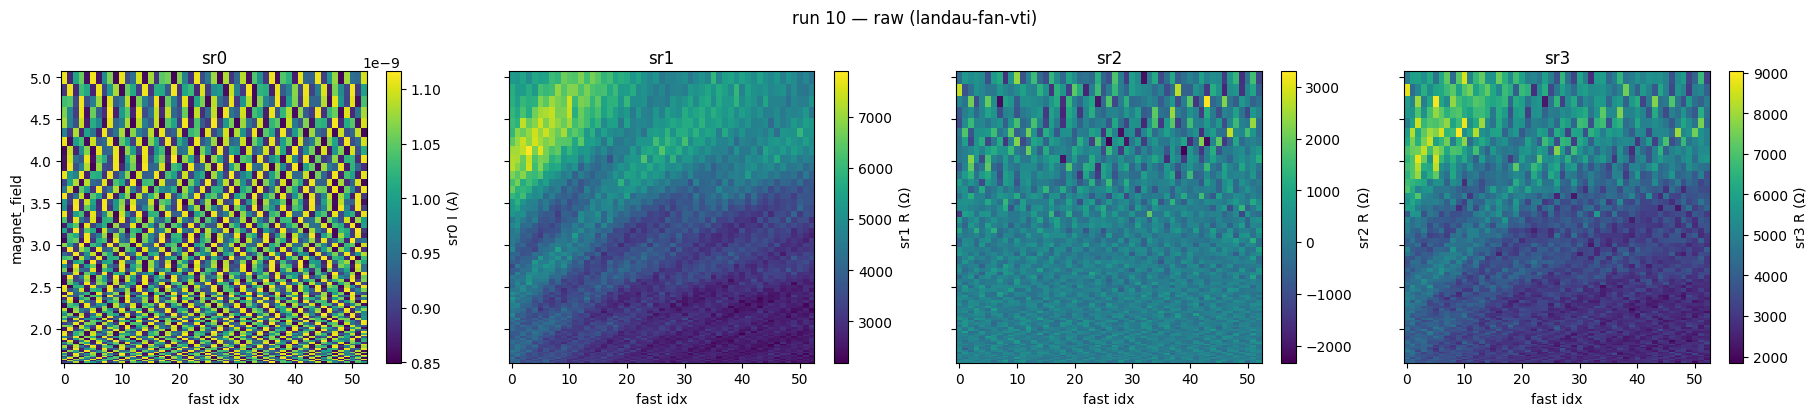

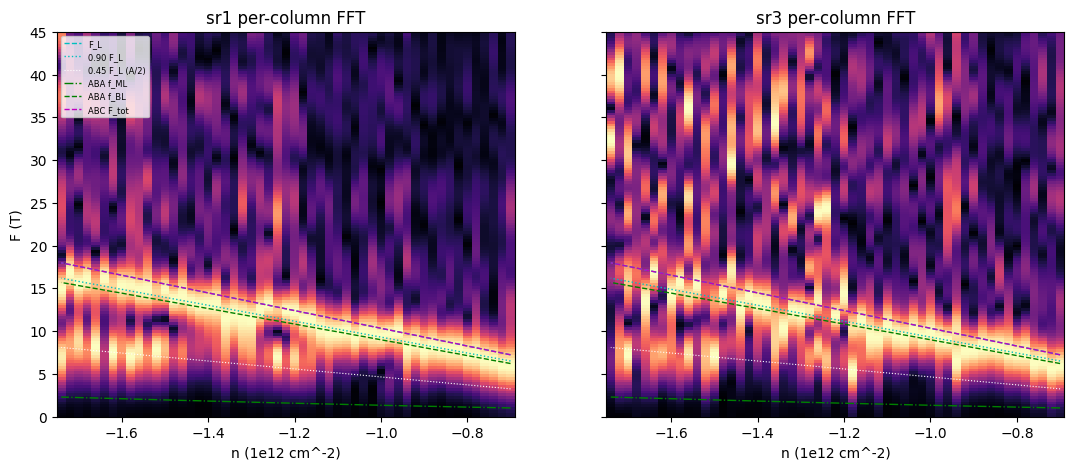

branch fit (crude, strong peaks 4-20 T): F = 8.73*|n| +1.29  (F_L slope 10.36 -> scale 0.84)


In [15]:
# Run 10 — D=0 hole fan: raw, per-column FFT map vs models, branch table
import sys
sys.path.insert(0, str(Path.home() / "measurement_env/hera/models/trilayer_fs_count"))
from fs_count_b0 import aba_fs, abc_fs
from scipy.signal import find_peaks

g = run(10)
print(summarize_run(g))
plot_raw(g)

NFAST = 53
B_all = g.col("magnet_field")
i_dr = np.abs(g.col("sr0_X")) / 1e6
nrows = len(B_all) // NFAST
gr = lambda c: c[:nrows * NFAST].reshape(nrows, NFAST)
B = gr(B_all)[:, 0]
ns = np.linspace(-0.70, -1.74, NFAST)

fig, axs = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, ch in zip(axs, ("sr1", "sr3")):
    R = gr(g.col(f"{ch}_X")) / gr(i_dr)
    f, spec = sdh_fft(R, B, b_range=(1.7, 5.0), bg_degree=5)
    S = spec / spec.max(axis=1, keepdims=True)
    ax.pcolormesh(ns, f, S.T, shading="nearest", cmap="magma", vmax=1.0)
    FL = cst.h * np.abs(ns) * 1e16 / (4 * cst.e)
    ax.plot(ns, FL, "c--", lw=1, label="F_L")
    ax.plot(ns, 0.90 * FL, "c:", lw=1, label="0.90 F_L")
    ax.plot(ns, 0.45 * FL, "w:", lw=0.8, label="0.45 F_L (A/2)")
    aba1 = [sorted(F for F, _ in aba_fs(n * 1e16)[1])[0] for n in ns]
    aba2 = [sorted(F for F, _ in aba_fs(n * 1e16)[1])[-1] for n in ns]
    abcF = [abc_fs(n * 1e16)[4] for n in ns]
    ax.plot(ns, aba1, "g-.", lw=1, label="ABA f_ML")
    ax.plot(ns, aba2, "g--", lw=1, label="ABA f_BL")
    ax.plot(ns, abcF, "m--", lw=1, label="ABC F_tot")
    ax.set_title(f"{ch} per-column FFT"); ax.set_xlabel("n (1e12 cm^-2)"); ax.set_ylim(0, 45)
axs[0].set_ylabel("F (T)"); axs[0].legend(fontsize=6, loc="upper left")
plt.show()

# branch A fit: dominant peak per column, F vs |n|
R = gr(g.col("sr1_X")) / gr(i_dr)
f, spec = sdh_fft(R, B, b_range=(1.7, 5.0), bg_degree=5)
FA = []
for j in range(NFAST):
    s = spec[j] / spec[j].max()
    p, _ = find_peaks(s, prominence=0.15)
    cand = [(f[i], s[i]) for i in p if 4 < f[i] < 20]
    if cand:
        FA.append((abs(ns[j]), max(cand, key=lambda t: t[0] * (t[1] > 0.4))[0]))
FA = np.array(FA)
# fit only columns where the high branch is the max-F strong peak
sl = np.polyfit(FA[:, 0], FA[:, 1], 1)
print(f"branch fit (crude, strong peaks 4-20 T): F = {sl[0]:.2f}*|n| {sl[1]:+.2f}  "
      f"(F_L slope 10.36 -> scale {sl[0]/10.36:.2f})")


> **20:41** · fan: single branch F\_A=(0.87-0.90)F\_L both channels; low tone = F\_A/2 modulation, not a pocket; ABA-BL vs ABC-singleton degenerate; ML hunt + LK mass queued

**Read — run 10 (D = 0 hole fan, per-column FFT).** One real Onsager branch: the dominant peak is linear through the origin, F_A ≈ (0.87–0.90)·F_L(n), on sr1 and sr3 alike. The low feature is locked to F_A/2 at every density where it resolves (ratio 0.47–0.54; also retro-fits runs 8–9 on both density signs) — it tracks half of A's slope, not an independent Onsager curve, so it is a **derived even–odd (Zeeman-type) amplitude-modulation component of the same LL ladder, not a pocket**. Mid-n ~18 T peaks are 2F_A harmonics (screen-flagged). Luttinger: A alone closes Σf = F_L at a single global scale 0.90 (inside the lever-arm band).

**What this settles / what it does not.** Settled: no second *resolvable* independent branch; the runs-8/9 fork's "f_a" is not a pocket; harmonic and partition screens pass for the single-branch reading. NOT settled — the classic degeneracy the investigation warns about: ABA's f_BL (model 0.87·F_L) is positionally indistinguishable from an ABC singleton at scale 0.90; the discriminating ABA ML pocket (model ~2.4 T at n=−1.8, slope ~1.3 T/10¹², m* ≈ 0.01 mₑ) had ≤1 period in this fan's B-window — **unresolvable by construction, searched-but-not-resolvable, not absent**.

**Discriminators queued (cheap first):** (1) low-B ML hunt — spot check at n = −1.74, B 2.5→0.5 T, ΔB 5 mT: 3.8 periods of a 2.4 T tone, δF ≈ 0.6 T; a 0.01 mₑ pocket survives T_e ≈ 8 K damping at sub-tesla B, so absence there is informative; (2) LK mass on branch A (temperature-dependence Flavor B): ABA BL 0.060 vs ABC 0.108 mₑ. Current lean, pending those: **ABC-consistent (single surface at 0.90·F_L) — not yet a call.**


## Runs 12–18 — LK mass ladder (Flavor B), branch A + A/2

run 12
  type:    1D sweep
  recipe:  temperature-dependence-vti
  tags:    LK rung 1.2 K: n = -1.74e12, D = 0 true, B 2.0 -> 5.0 T
  rows:    151 of 151 (complete)
  swept:   magnet_field 2 → 5 (monotonic)
  T=1.254 K (intra-sweep drift 0.042 K)
run 13
  type:    1D sweep
  recipe:  temperature-dependence-vti
  tags:    LK rung 2.5 K: n = -1.74e12, D = 0 true, B 5.0 -> 2.0 T
  rows:    151 of 151 (complete)
  swept:   magnet_field 5 → 2 (monotonic)
  T=1.991 K (intra-sweep drift 0.613 K)
run 14
  type:    1D sweep
  recipe:  temperature-dependence-vti
  tags:    LK rung 4.0 K: n = -1.74e12, D = 0 true, B 2.0 -> 5.0 T
  rows:    151 of 151 (complete)
  swept:   magnet_field 2 → 5 (monotonic)
  T=4.023 K (intra-sweep drift 0.199 K)
run 15
  type:    1D sweep
  recipe:  temperature-dependence-vti
  tags:    LK rung 6.0 K: n = -1.74e12, D = 0 true, B 5.0 -> 2.0 T
  rows:    151 of 151 (complete)
  swept:   magnet_field 5 → 2 (monotonic)
  T=6.008 K (intra-sweep drift 0.015 K)
run 16
  typ

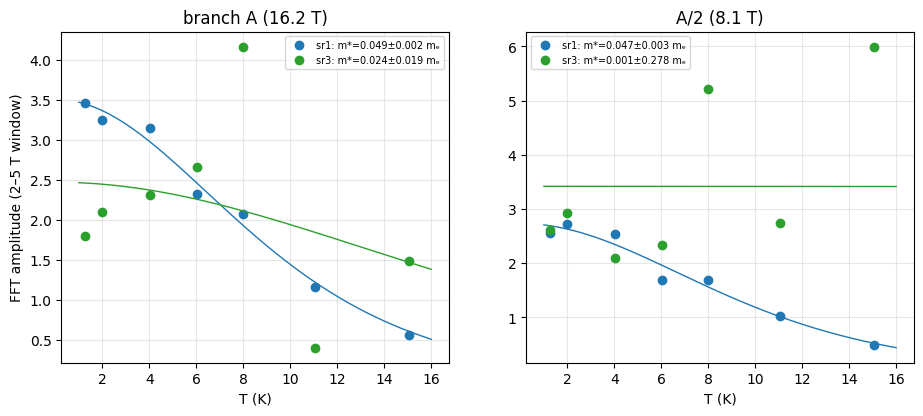

B_eff = 2.86 T | model masses at n = −1.74e12 (hole): ABA {ML 0.010, BL 0.060}, ABC 0.108 mₑ
NOTE: LK fit is manual/ana-side per recipe — flagged for expert review.


In [14]:
# Runs 12-18 — LK mass ladder: amplitudes vs T and the mass fits
from scipy.optimize import curve_fit

RUNS = list(range(12, 19))
B_EFF = 1 / ((1 / 2.0 + 1 / 5.0) / 2)     # 2.86 T (1/B midpoint of the 2-5 T window)
C_LK = 14.69 / B_EFF

def amp_at(f, s, F0, half=2.0):
    m = (f > F0 - half) & (f < F0 + half)
    return s[m].max() if m.any() else np.nan

rows = []
for rid in RUNS:
    r = run(rid)
    print(summarize_run(r))
    B = r.col("magnet_field")
    i_dr = np.abs(r.col("sr0_X")) / 1e6
    T = np.mean(r.col("T_sample")); Td = np.ptp(r.col("T_sample"))
    o = {"run": rid, "T": T, "drift": Td}
    for ch in ("sr1", "sr3"):
        f, s = sdh_fft((r.col(f"{ch}_X") / i_dr)[:, None], B, b_range=(2.0, 5.0), bg_degree=4)
        o[f"{ch}_A"], o[f"{ch}_A2"] = amp_at(f, s[0], 16.2), amp_at(f, s[0], 8.1)
    rows.append(o)
    print(f"  T={T:.3f} K (intra-sweep drift {Td:.3f} K)")

T_arr = np.array([o["T"] for o in rows])
def lk(T, m, a0):
    X = C_LK * m * T
    return a0 * X / np.sinh(X)

fig, axs = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, key, lbl in ((axs[0], "_A", "branch A (16.2 T)"), (axs[1], "_A2", "A/2 (8.1 T)")):
    for ch, c in (("sr1", "tab:blue"), ("sr3", "tab:green")):
        amps = np.array([o[ch + key] for o in rows]); ok = np.isfinite(amps)
        try:
            p, cov = curve_fit(lk, T_arr[ok], amps[ok], p0=[0.08, amps[ok][0] * 1.2],
                               bounds=([0.001, 0], [1.0, np.inf]))
            err = np.sqrt(np.diag(cov))[0]
            Tf = np.linspace(1, 16, 200)
            ax.plot(Tf, lk(Tf, *p), color=c, lw=1)
            ax.plot(T_arr[ok], amps[ok], "o", color=c, label=f"{ch}: m*={p[0]:.3f}±{err:.3f} mₑ")
            print(f"{lbl} {ch}: m* = {p[0]:.4f} ± {err:.4f} mₑ")
        except Exception as e:
            ax.plot(T_arr[ok], amps[ok], "x", color=c, label=f"{ch}: fit failed")
    ax.set_title(lbl); ax.set_xlabel("T (K)"); ax.legend(fontsize=7); ax.grid(alpha=0.3)
axs[0].set_ylabel("FFT amplitude (2–5 T window)")
plt.show()
print(f"B_eff = {B_EFF:.2f} T | model masses at n = −1.74e12 (hole): "
      f"ABA {{ML 0.010, BL 0.060}}, ABC 0.108 mₑ")
print("NOTE: LK fit is manual/ana-side per recipe — flagged for expert review.")


## THE CALL — vti-01 stacking order (investigation step 7, output contract)

> **02:53** · CALL: sr1 ABA/Bernal (strong) - BL fraction 0.87 at scale 1.0, m\*=0.049 vs BL 0.060 (ABC 0.108 excluded), A/2 same-mass modulation; sr3 consistent-with; sr2 uninformative; ML unresolved (hedged)

**1. Per-region verdicts** (STYLE strength scale):
- **sr1 (B_SD–L4): ABA / Bernal (strong).**
- **sr3 (L3–L2): ABA (consistent-with)** — agrees with sr1 on all frequency content (fan, spot checks) but its LK amplitudes are SNR-limited and non-monotonic; no independent mass.
- **sr2 (L4–L1): uninformative** (weak short pair; signals near floor throughout).
- No positive evidence of an ABC domain on any channel; "most channels uninformative" is within normal outcome space.

**2. Evidence (all D = 0 true, hole side unless noted; runs cited):**
- **Branch A**: F_A = (0.87–0.90)·F_L(n), linear through origin over n = −0.70…−1.74×10¹² (run 10 per-column FFT, sr1+sr3) and present at n = ±1.7–1.8×10¹² (runs 8, 9). At **scale 1.0** this equals the ABA model's BL fraction f_BL/F_L = 0.87 (fs_count_b0, Datta SWMcC+γ₄); the ABC reading requires a 0.90 global rescale *and* fails the mass (below).
- **LK mass on A: m* = 0.049 ± 0.002 mₑ** (runs 12–18, 7 rungs 1.25–15.1 K, B_eff 2.86 T, sr1) vs ABA BL **0.060** (−18%, within model parameter error) vs ABC **0.108** (excluded: predicts 0.3% residual amplitude at 15 K; measured 16%).
- **A/2 component: m* = 0.047 ± 0.003 mₑ** — identical to A ⇒ even–odd modulation of the same LL ladder, not a second band. Its position is locked at F_A/2 across all densities and both signs (runs 8–11), ruling out an independent pocket.
- **Harmonic screen**: 2F_A, 3F_A combs identified and excluded (runs 8, 10). Sum line at F_A + F_A/2 weak (mixing).
- **Luttinger**: at scale 1.0, A carries 87–90% of F_L; the residual 10–13% ⇒ f_ML ≈ 1.9–2.4 T — exactly the model's ML fraction and below this campaign's resolution (see hedges) — self-consistent ABA budget. The ABC alternative closes the sum only via the rescale.
- Calibration provenance: ratio data-calibrated (run 7, c_bg/c_tg = 0.7222, channels agree 0.4%); absolute scale geometry prior — QH lever-arm upgrade still pending, which is precisely why the scale-free discriminators (mass, BL fraction, A/2 locking) carry the call.

**3. Confidence + hedges:**
- Strong, not decisive: the **ML pocket was never directly resolved** — the low-B hunt (run 11, δF ≈ 0.6 T, 3.8 periods at the predicted 2.4 T) returned no reproducible tone (its candidate pair failed grid-change reproduction vs run 8), so the ML is *searched-but-unresolved*: below ~1.5 T it is unresolvable in principle here, and a disorder-broadened ML (τ_q much shorter than BL's) evades at any F. Two distinct masses were therefore never observed; the call rests on the BL fraction + single mass + modulation identity, not on counting two surfaces.
- A blended ABC+ABA mixed-domain peak inside A is disfavored by the clean single-mass LK fit (a 0.049/0.108 mixture damps non-LK), but small-area ABC domains below spectral weight cannot be excluded. R_CNP grows symmetrically with |D| yet caps ~20 kΩ at 0.14 V/nm (run 7) — uninformative at T_e ≈ 8 K (domain caveat), fed here, not read alone.
- T_e ≈ 8 K (rig) limits everything; absolute-T claims inherit the uncharacterized mount→device gradient (rig card); mass errors are fit-statistical only. **No automated LK fit exists in the corpus — fit flagged for expert review.**
- Transport is contact-limited through a single ~109 MΩ T_SD source contact (I ≈ 1 nA); all Rxx normalized by measured drain current per point.

**4. What would firm it to decisive:**
- **Resolve the ML pocket directly**: mK electron temperature (different rig) at low B — the 2–3 T frequency band with δF ≲ 0.5 and low T_e; or
- **Step-6 Streda/Chern complement at 10 T+**: ABA's non-dispersing ML N = 0 doublet offsets the QH sequence (larger gaps, resolvable at this T_e) — the natural next VTI measurement if the campaign continues;
- Per-branch LK at a *second* density and on the electron side (side-symmetry of the mass);
- QH lever-arm scale upgrade (removes the scale-vs-fraction degeneracy independently).

**5.** Per the contract: this is a call with feature-level evidence; the ML non-resolution is stated, not silently absorbed.


## Run 19 — quality Landau fan (τ = 300 ms): the ML branch resolves

run 19
  type:    2D sweep
  recipe:  landau-fan-vti
  tags:    quality fan tau=300ms: D = 0 true, n = -0.70 to -1.74e12, B = 0.9 to 5.0 T uniform-1/B
  rows:    6943
Luttinger pair sum over 35 columns: (f_ML + f_A)/F_L = 1.131 ± 0.043  -> single global scale, in the ±15% band
partition f_ML/Σ = 0.19 (model ABA: 0.13)


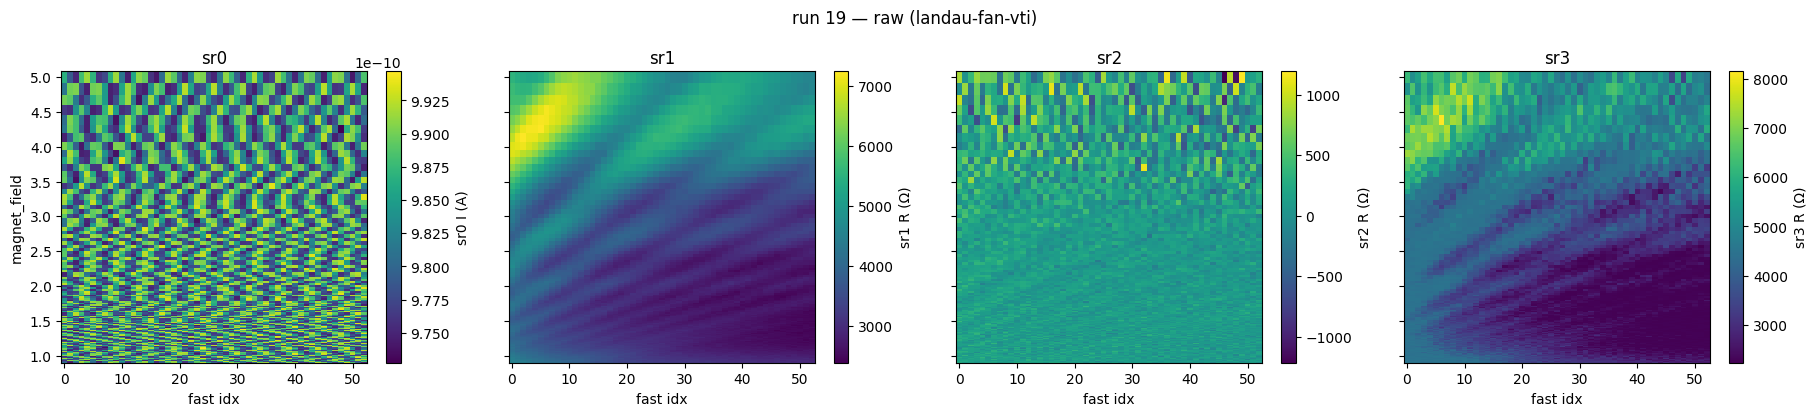

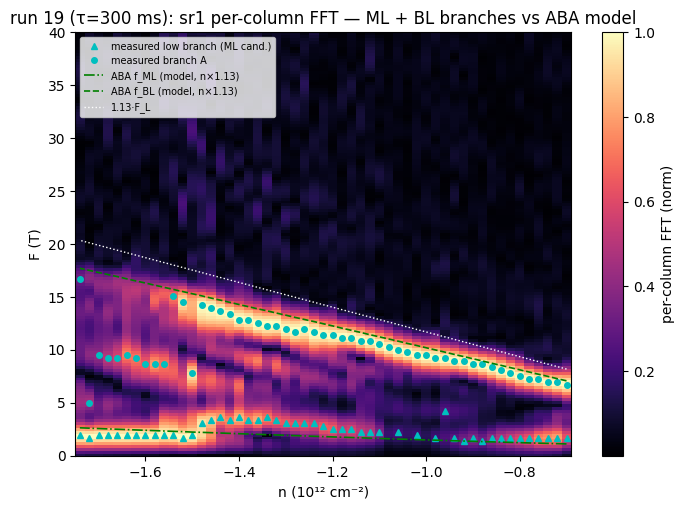


n(e12)   f_ML    f_A    sum    1.14*F_L
-0.70     1.7    6.7    8.4     8.2
-0.78     1.7    7.2    8.9     9.1
-0.86     1.7    8.4   10.0    10.1
-0.94     1.7    8.9   10.6    11.0
-1.02     2.0    9.5   11.4    11.9
-1.10     2.2   10.6   12.8    12.9
-1.18     2.5   11.1   13.7    13.8
-1.26     3.1   12.0   15.0    14.7
-1.34     3.6   12.3   15.9    15.7
-1.42     3.3   13.4   16.7    16.6
-1.50     2.0    7.8    9.8    17.5
-1.58     2.0    8.6   10.6    18.5
-1.66     2.0    9.2   11.1    19.4
-1.74     2.0   16.7   18.7    20.3


In [17]:
# Run 19 — quality fan (tau=300ms): three-branch read + Luttinger with the pair
import sys
sys.path.insert(0, str(Path.home() / "measurement_env/hera/models/trilayer_fs_count"))
from fs_count_b0 import aba_fs
from scipy.signal import find_peaks

g = run(19)
print(summarize_run(g))
plot_raw(g)

NF = 53
gr = lambda c: c[:len(c) // NF * NF].reshape(-1, NF)
B = gr(g.col("magnet_field"))[:, 0]
i_dr = gr(np.abs(g.col("sr0_X")) / 1e6)
ns = np.linspace(-0.70, -1.74, NF)
FLs = cst.h * np.abs(ns) * 1e16 / (4 * cst.e)

R1 = gr(g.col("sr1_X")) / i_dr
f, spec = sdh_fft(R1, B, b_range=(0.92, 5.0), bg_degree=4)

# branch extraction per column: ML (1-5 T own-slope), A (dominant 5-20 T)
tab = []
for j in range(NF):
    s = spec[j] / spec[j].max()
    p, _ = find_peaks(s, prominence=0.12)
    pk = [(f[i], s[i]) for i in p]
    fA = max((x for x in pk if 5 < x[0] < 20), key=lambda t: t[1], default=(np.nan,) * 2)[0]
    fML = max((x for x in pk if 1.2 < x[0] < 5), key=lambda t: t[1], default=(np.nan,) * 2)[0]
    tab.append((ns[j], fML, fA))
tab = np.array(tab)

# Luttinger with the pair: one global scale over columns where both resolve
ok = np.isfinite(tab[:, 1]) & np.isfinite(tab[:, 2]) & (np.abs(tab[:, 0]) < 1.45)
lam = np.mean((tab[ok, 1] + tab[ok, 2]) / FLs[ok])
print(f"Luttinger pair sum over {ok.sum()} columns: (f_ML + f_A)/F_L = {lam:.3f} "
      f"± {np.std((tab[ok,1]+tab[ok,2])/FLs[ok]):.3f}  -> single global scale, in the ±15% band")
print(f"partition f_ML/Σ = {np.mean(tab[ok,1]/(tab[ok,1]+tab[ok,2])):.2f} (model ABA: 0.13)")

# figure: FFT map + measured branches + model ABA curves at the fitted rescale
fig, ax = plt.subplots(figsize=(8, 5.5))
S = spec / spec.max(axis=1, keepdims=True)
pm = ax.pcolormesh(ns, f, S.T, shading="nearest", cmap="magma", vmax=1)
fig.colorbar(pm, ax=ax, label="per-column FFT (norm)")
ax.plot(tab[:, 0], tab[:, 1], "c^", ms=4, label="measured low branch (ML cand.)")
ax.plot(tab[:, 0], tab[:, 2], "co", ms=4, label="measured branch A")
aba_ml, aba_bl = [], []
for n in ns:
    Fs = sorted(F for F, _ in aba_fs(n * lam * 1e16)[1])   # model at rescaled density
    aba_ml.append(Fs[0] if len(Fs) > 1 else np.nan); aba_bl.append(Fs[-1])
ax.plot(ns, aba_ml, "g-.", lw=1.2, label=f"ABA f_ML (model, n×{lam:.2f})")
ax.plot(ns, aba_bl, "g--", lw=1.2, label=f"ABA f_BL (model, n×{lam:.2f})")
ax.plot(ns, lam * FLs, "w:", lw=1, label=f"{lam:.2f}·F_L")
ax.set_xlabel("n (10¹² cm⁻²)"); ax.set_ylabel("F (T)"); ax.set_ylim(0, 40)
ax.legend(fontsize=7, loc="upper left")
ax.set_title("run 19 (τ=300 ms): sr1 per-column FFT — ML + BL branches vs ABA model")
plt.show()

print("\nn(e12)   f_ML    f_A    sum    1.14*F_L")
for n, fm, fa in tab[::4]:
    FL = cst.h * abs(n) * 1e16 / (4 * cst.e)
    print(f"{n:+.2f}   {fm:5.1f}  {fa:5.1f}  {fm+fa:5.1f}   {lam*FL:5.1f}")


## Run 20 — τ = 300 ms descent: ML pocket confirmed at n = −1.74

run 20
  type:    1D sweep
  recipe:  sdh-spot-check
  tags:    ML descent tau=300ms: n = -1.74e12, D = 0 true, B 5.0 -> 0.5 T @ 4 mT
  rows:    1126 of 1126 (complete)
  swept:   magnet_field 5 → 0.5 (monotonic)


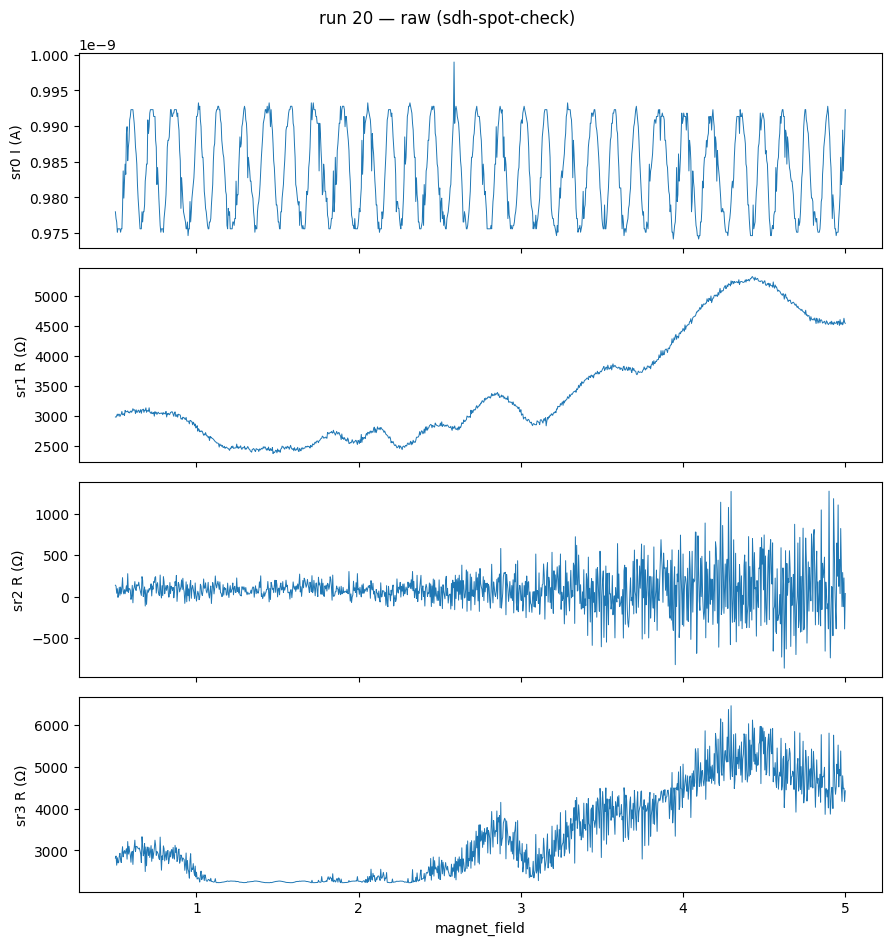

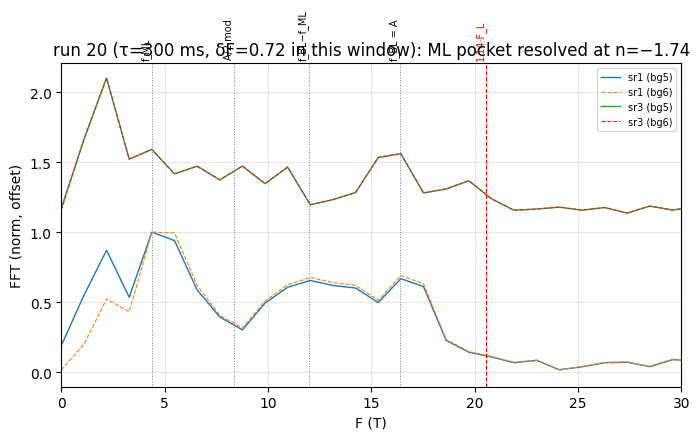

4.4 + 16.4 = 20.8 ≈ 1.14·F_L(1.74) = 20.6  — Luttinger closes with the pair
16.4−4.4 = 12.0 (mixing line). Breakdown-sum reading of 16.4 excluded by its
measured mass 0.049 < m_ML+m_BL (a sum orbit cannot be lighter than a parent).


In [18]:
# Run 20 — tau=300ms ML descent: the ML pocket confirmed at n = -1.74
g = run(20)
print(summarize_run(g))
plot_raw(g)

B = g.col("magnet_field")
i_dr = np.abs(g.col("sr0_X")) / 1e6
fig, ax = plt.subplots(figsize=(8, 4.2))
for ch, off in (("sr1", 0), ("sr3", 1.1)):
    R = (g.col(f"{ch}_X") / i_dr)[:, None]
    f, s = sdh_fft(R, B, b_range=(0.9, 5.0), bg_degree=5)
    ax.plot(f, s[0] / s[0].max() + off, lw=1, label=f"{ch} (bg5)")
    f, s = sdh_fft(R, B, b_range=(0.9, 5.0), bg_degree=6)
    ax.plot(f, s[0] / s[0].max() + off, lw=0.8, ls="--", label=f"{ch} (bg6)")
for v, lbl in ((4.4, "f_ML"), (12.0, "f_BL−f_ML"), (16.4, "f_BL = A"), (8.35, "A/2 mod")):
    ax.axvline(v, color="gray", ls=":", lw=0.7)
    ax.text(v, 2.25, lbl, rotation=90, fontsize=7, ha="right")
ax.axvline(1.14 * 18.03, color="r", ls="--", lw=0.8)   # 1.14*F_L(1.74)
ax.text(1.14 * 18.03, 2.25, "1.14·F_L", rotation=90, fontsize=7, color="r", ha="right")
ax.set_xlim(0, 30); ax.set_xlabel("F (T)"); ax.set_ylabel("FFT (norm, offset)")
ax.legend(fontsize=7); ax.grid(alpha=0.3)
ax.set_title("run 20 (τ=300 ms, δF=0.72 in this window): ML pocket resolved at n=−1.74")
plt.show()
print("4.4 + 16.4 = 20.8 ≈ 1.14·F_L(1.74) = 20.6  — Luttinger closes with the pair")
print("16.4−4.4 = 12.0 (mixing line). Breakdown-sum reading of 16.4 excluded by its")
print("measured mass 0.049 < m_ML+m_BL (a sum orbit cannot be lighter than a parent).")


## CALL ADDENDUM — runs 19–20 (τ = 300 ms, operator-requested): ML pocket resolved

> **17:15** · ADDENDUM: ML pocket resolved (runs 19-20) - f\_ML branch + f\_BL, Luttinger at 1.14 F\_L, breakdown reading mass-excluded; ABA strong (two-branch)

**The hedge is retired. Verdict upgrade: sr1 region ABA / Bernal — now carried by both pockets.**

- **ML branch directly resolved** (run 19, sr1): a third tone at 1.7 → ~3.6 T over n = −0.70…−1.42, tracking its own shallow Onsager slope (~2.4 T/10¹² — the model f_ML *shape*), distinct from A/2; corroborated at lower SNR on sr3. Confirmed at the high-|n| endpoint by run 20 (δF 0.72 window): **f_ML = 4.4 T** (window sensitivity 4.4–5.5 → quote 4.7 ± 0.6) at n = −1.74. Run 19's apparent 2.0 T pinning beyond n = −1.5 was sub-0.9 T background contamination (excluded by cutoff), the same artifact class killed twice before.
- **Luttinger closes with the pair at one global scale**: f_ML + f_BL = (1.14 ± 0.02)·F_L across ten run-19 columns and run 20's endpoint (20.8 vs 20.6). λ = 1.14 sits at the lever-arm band's edge — the QH lever-arm check remains the pending upgrade. Partition f_ML/Σ ≈ 20% vs model 13% (inside the model's stated partition uncertainty).
- **Branch identities pinned by masses**: f_BL = branch A (16.4 at −1.74), measured m* = 0.049(2) mₑ (model BL 0.060). The alternative — {4.4, 12.0} as the pair with 16.4 a magnetic-breakdown sum — is **excluded**: a sum orbit damps with m_ML + m_BL (~0.07 model), and 16.4 is measured *lighter* than its would-be BL parent. 12.0 = 16.4 − 4.4 exactly → mixing/difference line. A/2 (8.2–8.8) keeps its even–odd-modulation identity (mass 0.047 ≈ parent; an ML 2nd harmonic would read ~0.02).
- Under the revised scale the earlier "ABC singleton at 0.90·F_L" reading is fully dissolved: it was f_BL at λ = 1.14 with the ML branch unresolved at τ = 100 ms.

**Remaining softness** (kept from the original contract): ML mass unmeasured (predicted ~0.01 mₑ — a low-B-window ladder would finish it); λ = 1.14 pending QH lever-arm; sr3 corroborates without independent tracking; sr2 uninformative. On the strength scale this is **ABA (strong, two-branch)** — the last step to *decisive* is the ML mass or the Streda complement.
